# Reconstruction vs contrastive vs prediction: what was run, what came out, and what it looks like

Display only. It reads the frozen HPC launch (cached test-set features and run logs) and the committed result CSVs.
Nothing is retrained, and nothing here changes a verdict.

**Contents**

0. **Recap**: every experiment run so far, and every verdict
1. **The data**: the three latent processes; the exact decomposition of the observations into signal, nuisance and
   noise for every condition; how big and how fast each part is; why fast vs slow nuisance matters for prediction
2. **Results for every variation**: every metric for every condition × learner × seed (heatmaps, per-seed dots,
   paired effects, dose response, full tables)
3. **Latent spaces**: PCA, t-SNE and the linear-probe axis for every learner and condition
4. **Time domain**: linear regime axis vs dominant direction vs HMM decoding
5. **Training dynamics**
6. **The other experiments**: preflight control audit on the fresh series, the exploratory pilot (context only,
   never pooled) and the CPC trainability check

## 0. Recap

### Experiments run

| # | Experiment | What | Status | Files |
|---|---|---|---|---|
| 1 | Control audit | oracle, raw features, untrained encoder on all 5 conditions; no learner trained | done before pre-registration amendment; pilot evaluation series | `cpbench_results/recon_vs_pred_audit.csv` |
| 2 | Local pilot | N0, F2, S2 × 6 learners × 1 seed × 3k steps; legacy code (pre-`audit_v2`) | **exploratory**; motivated the amendment | `cpbench_results/recon_vs_pred_pilot.csv` |
| 3 | Pilot-informed amendment | H1 → single-window MLP probe; H2 → MLP nuisance probe; H3 split into H3a (legacy) and H3b; fresh evaluation series (`eval_seed` 20261016) | frozen in f4b3d41 before HPC training | README |
| 4 | CPC trainability check | CPC, F2, 3k steps, temperature {0.1, 0.5} × lr {3e-4, 1e-4}; label-free selection | no setting passed: CPC pre-declared "failed to train" | `cpbench_results/recon_vs_pred_cpc_check.csv` |
| 5 | **Confirmatory HPC run** | 5 conditions × 6 learners × 3 seeds × 20k steps (90 runs) + 4 controls × 5 conditions; preflight control gates on the fresh series | **all gates pass; verdicts below** | `cpbench_results/recon_vs_pred_hpc*.csv` |
| 6 | Linear identifiability | ridge vs MLP R² from features to the true rotation latent and to the regime statistic | **exploratory, post hoc** | `cpbench_results/recon_vs_pred_identifiability.csv` |

**Conditions** (only the nuisance changes; the signal, renderings and noise are identical):

| | N0 | F1 | F2 | S1 | S2 |
|---|---|---|---|---|---|
| nuisance timescale | none | fast, tau = 16 | fast, tau = 16 | slow, tau = 2000 | slow, tau = 2000 |
| nuisance amplitude sigma_n | 0 | 1 | 2 | 1 | 2 |

**Learners:** reconstruction (AE, VAE), prediction (JEPA separate / shared encoders), contrastive with a future
target (CPC) and with a same-time target (TS2Vec); controls: untrained encoder, raw windows, raw lag covariance, oracle.

In [1]:
import os, sys, json, glob
L = os.environ.get("CPBENCH_LAUNCH", "sweeps/recon_vs_pred/launch_20261016T200516Z")
os.environ["CPBENCH_CACHE"] = os.path.abspath(os.path.join(L, "cache"))      # before importing cpbench
RUNS = os.path.abspath(os.path.join(L, "runs"))
sys.path[:0] = ["experiments/recon_vs_pred", "."]
import cpbench  # noqa: F401
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import balanced_accuracy_score
from cpbench import Benchmark
from cpbench.data import Dataset
from cpbench.data.windows import majority_labels
from cpbench.detectors import make_detector
from design import CONDITIONS, CONTROLS, LEARNERS, W, GAP, TAU, NOISE, EVAL_SEED, dataset
from experiment import learner, control, FAMILY, PRED, RECON, _boot_diff

# palette: one hue per family (validated first three slots of the reference palette), gray controls,
# marker shape separates the two learners of a family; regime = blue / red poles; signed values = diverging.
BLUE, ORANGE, AQUA, RED, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#8a8984"
INK, INK2, MUTED, RULE, MID = "#0b0b0b", "#52514e", "#8a8984", "#e4e3df", "#f0efec"
FAMC = {"reconstruction": BLUE, "prediction": ORANGE, "contrastive (future target)": AQUA,
        "contrastive (same-time target)": AQUA, "control": GRAY}
MARK = dict(ae="o", vae="s", jepa_separate="o", jepa_shared="s", cpc="o", ts2vec="s",
            untrained="v", raw_flat="D", raw_lagcov="P", oracle="*")
REG = [BLUE, RED]
DIV = LinearSegmentedColormap.from_list("div", [BLUE, MID, RED])
SEQ = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#104281"])
ORDER = ["ae", "vae", "jepa_separate", "jepa_shared", "cpc", "ts2vec", "untrained", "raw_flat", "raw_lagcov", "oracle"]
TRAINED = ORDER[:6]
CONDS = list(CONDITIONS)
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "font.size": 8.5, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "axes.titlesize": 9,
                     "axes.grid": False, "legend.frameon": False, "image.interpolation": "nearest"})
def learner_handles(keys=ORDER):
    return [Line2D([], [], ls="", marker=MARK[k], color=FAMC[FAMILY[k]], mec="white", mew=0.6, ms=7, label=k) for k in keys]

benches = {c: Benchmark(Dataset(dataset(c)), out=RUNS, log=lambda *a: None, load_only=True) for c in CONDS}
def spec(key, seed=0):
    return control(key) if key in CONTROLS else learner(key, 20000, seed)
def feats(c, key, seed=0):
    v, starts = benches[c].features(spec(key, seed))
    return v["features"].astype(np.float64), starts
_, STARTS = feats("N0", "raw_flat")
def win_regime(c):  return majority_labels(benches[c].test["S_s"], STARTS, W, 2)          # (R, T)
def win_nuis(c):    return benches[c].test["nuisance"][:, STARTS + W // 2, 0] * CONDITIONS[c][1]

res = pd.read_csv("cpbench_results/recon_vs_pred_hpc.csv")
ident = pd.read_csv("cpbench_results/recon_vs_pred_identifiability.csv")
df = res.merge(ident[["cond", "learner", "seed", "lat_lin", "lat_mlp", "stat_lin", "stat_mlp"]], on=["cond", "learner", "seed"])
assert df.protocol.nunique() == 1 and (df.eval_seed == EVAL_SEED).all()
print(L, "|", len(df), "rows |", df.protocol.iloc[0], "| eval_seed", EVAL_SEED)

/projects/b5ci/Quique/JEPA-LINEAR/sweeps/recon_vs_pred/launch_20261016T200516Z | 110 rows | audit_v2+pilot_informed_v1 | eval_seed 20261016


### Verdicts of the confirmatory run

In [2]:
v = pd.read_csv(os.path.join(L, "verdicts.csv"))
with pd.option_context("display.max_colwidth", 160, "display.width", 250, "display.max_rows", 100):
    display(v)

,test,verdict,numbers
0,gate: complete confirmatory protocol,pass,"missing=0, duplicates=False, finite=True, budget=True, protocol=True, fresh eval series=True"
1,gate: oracle HMM acc >= 0.95 everywhere,pass,"N0 0.959, F1 0.959, F2 0.959, S1 0.959, S2 0.959"
2,gate: some trained learner has probe >= 0.9 on N0,pass,best mean linear probe 0.981 (jepa_shared)
3,"gate: no collapse (eff_rank > 2, final loss < loss at 1k; excl. pre-declared cpc)",pass,-
4,"reported: pre-declared failed-to-train methods (cpc), collapse criterion",info,0/15 runs fail it: -
5,control F1: family probe_mlp_single - untrained (0.609) >= 0.05,info,"pred +0.352: keeps regime, recon +0.330: keeps regime"
6,control F1: family probe - untrained (0.605) >= 0.05,info,"pred +0.369: keeps regime, recon -0.049: does not meet retention criterion"
7,control F2: family probe_mlp_single - untrained (0.548) >= 0.05,info,"pred +0.420: keeps regime, recon +0.399: keeps regime"
8,control F2: family probe - untrained (0.540) >= 0.05,info,"pred +0.433: keeps regime, recon +0.046: does not meet retention criterion"
9,control N0: family probe_mlp_single - untrained (0.714) >= 0.05,info,"pred +0.249: keeps regime, recon +0.243: keeps regime"


## 1. The data

`observed = signal + nuisance + noise`, then per-channel standardisation.

- **signal** = random Fourier rendering (64 channels) of the 2-D **rotation latent**. The regime is the rotation
  direction (ω = ±0.12 rad/sample, period about 52 samples, damping 0.98).
- **nuisance** = sigma_n × an independent random Fourier rendering of a 2-D **AR(1) latent**, either fast (tau = 16) or
  slow (tau = 2000). It is independent of the regime.
- **noise** = white, sigma 0.3 per channel.

### 1a. The three latent processes

These are the hidden variables before rendering, on the same axes. Shading marks regime 1. The rotation (top) is
identical in every condition; only which nuisance is added, and how much of it, changes.

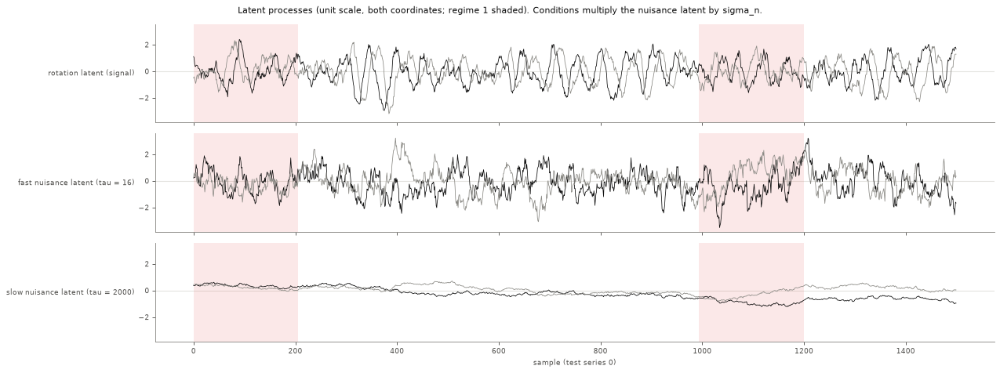

In [3]:
t = benches["F2"].test; ts = benches["S2"].test
seg = slice(0, 1500); S = t["S_s"][0, seg]; x = np.arange(len(S))
assert np.allclose(t["latent"], ts["latent"])            # same rotation latent in every condition
rows = [("rotation latent (signal)", t["latent"][0, seg]), ("fast nuisance latent (tau = 16)", t["nuisance"][0, seg]),
        ("slow nuisance latent (tau = 2000)", ts["nuisance"][0, seg])]
fig, ax = plt.subplots(3, 1, figsize=(16, 6), sharex=True, sharey=True)
for a, (name, z) in zip(ax, rows):
    a.fill_between(x, 0, 1, where=S == 1, transform=a.get_xaxis_transform(), color=RED, alpha=0.12, lw=0)
    a.plot(x, z[:, 0], color=INK, lw=0.7); a.plot(x, z[:, 1], color=MUTED, lw=0.7)
    a.set_ylabel(name, rotation=0, ha="right", va="center"); a.axhline(0, color=RULE, lw=1, zorder=0)
ax[-1].set_xlabel("sample (test series 0)")
fig.suptitle("Latent processes (unit scale, both coordinates; regime 1 shaded). Conditions multiply the nuisance latent by sigma_n.", fontsize=10)
plt.tight_layout(); plt.show()

### 1b. What each condition adds to the observations

The observation decomposes **exactly** into its three parts. Each part is re-simulated with the same random draws,
with the other parts switched off (checked to 1e-6). Every heatmap shares one colour scale, in raw units before
standardisation, so the panels can be compared directly. Rows show signal, nuisance, noise, their sum, and finally
what the learners actually receive (the standardised observation). It shows 400 samples around a regime switch, with
the regime marked above each column (blue 0, red 1). The signal row is identical across conditions by construction.

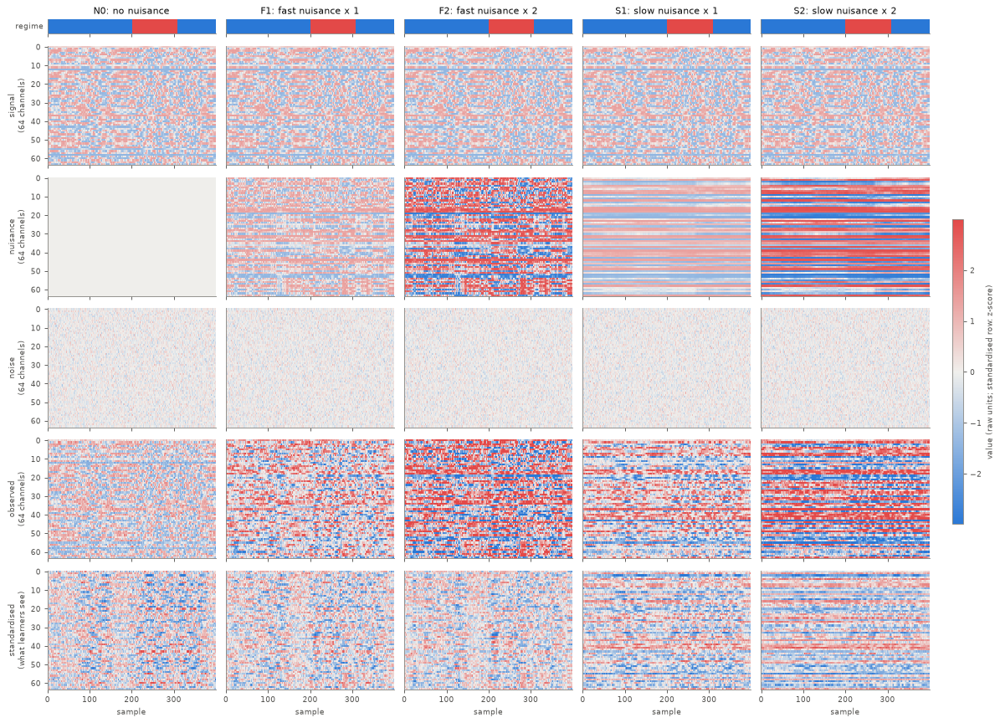

In [4]:
def components(c, n=1500, R=1, tag=99):
    """obs = signal + nuisance + noise exactly (before standardisation); same regime path, latents and noise draws."""
    def draw(sigma_n, noise, standardize=False):
        d = dataset(c); d["standardize"] = standardize
        d["sources"][1]["scale"] = sigma_n; d["transforms"][1]["sigma"] = noise
        return Dataset(d).sample(R, n, np.random.default_rng([EVAL_SEED, tag]))
    sn = CONDITIONS[c][1]
    full, sig = draw(sn, NOISE), draw(0.0, 0.0)
    nuis = draw(sn, 0.0)["obs"] - sig["obs"]; noise = draw(0.0, NOISE)["obs"] - sig["obs"]
    assert np.abs(full["obs"] - (sig["obs"] + nuis + noise)).max() < 1e-4
    return dict(signal=sig["obs"], nuisance=nuis, noise=noise, observed=full["obs"],
                standardised=draw(sn, NOISE, True)["obs"], S=full["S_s"], latent=full["latent"], u=full["nuisance"])
COMP = {c: components(c) for c in CONDS}
PARTS = ["signal", "nuisance", "noise", "observed"]
sw = 200 + int(np.flatnonzero(np.diff(COMP["N0"]["S"][0, 200:]) != 0)[0])     # first regime switch after sample 200
seg = slice(sw - 200, sw + 200)
vmax = 3 * COMP["N0"]["signal"].std()
fig, ax = plt.subplots(6, 5, figsize=(17, 13), sharex=True, gridspec_kw=dict(height_ratios=[0.12, 1, 1, 1, 1, 1], hspace=0.12, wspace=0.06))
for j, c in enumerate(CONDS):
    C = COMP[c]; S = C["S"][0, seg]
    ax[0, j].imshow(S[None], aspect="auto", cmap=mpl.colors.ListedColormap(REG), vmin=0, vmax=1)
    ax[0, j].set_yticks([]); sp, sn = CONDITIONS[c]
    ax[0, j].set_title(f"{c}: {'no nuisance' if sn == 0 else f'{sp} nuisance x {sn:g}'}", fontsize=10)
    for i, part in enumerate(PARTS + ["standardised"], 1):
        im = ax[i, j].imshow(C[part][0, seg].T, aspect="auto", cmap=DIV, vmin=-vmax, vmax=vmax)
        if j == 0: ax[i, j].set_ylabel(part + ("\n(what learners see)" if part == "standardised" else "\n(64 channels)"))
        else: ax[i, j].set_yticks([])
    ax[-1, j].set_xlabel("sample")
ax[0, 0].set_ylabel("regime", rotation=0, ha="right", va="center")
fig.subplots_adjust(right=0.9)
fig.colorbar(im, cax=fig.add_axes([0.92, 0.3, 0.01, 0.35]), label="value (raw units; standardised row: z-score)")
plt.show()

### 1c. One channel, one context–target pair

This shows the channel with the strongest signal, first 400 samples. Lines are the signal (black), the nuisance (orange) and their sum
with noise (gray). The blue span is a context window and the orange span its target, 96 samples later. Fast nuisance
wiggles within each window and is unrelated between context and target. Slow nuisance is a near-constant offset that
carries from context to target. The rendering is a bounded (Fourier) map, so large nuisance values saturate.

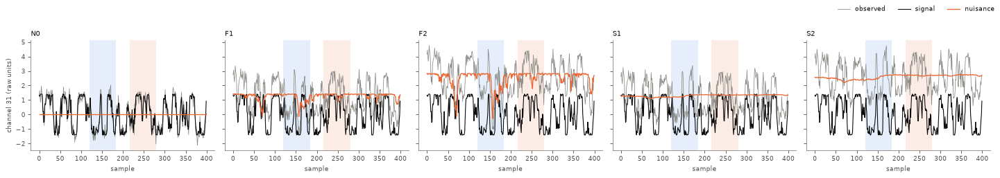

In [5]:
CH = int(COMP["N0"]["signal"][0].var(0).argmax())                                  # channel with the strongest signal
fig, ax = plt.subplots(1, 5, figsize=(18, 3.2), sharey=True)
x = np.arange(400)
for a, c in zip(ax, CONDS):
    C = COMP[c]
    for lo, col in ((0, BLUE), (W + GAP, ORANGE)):
        a.axvspan(lo + 120, lo + 120 + W, color=col, alpha=0.12, lw=0)
    a.plot(x, C["observed"][0, :400, CH], color=MUTED, lw=0.7, label="observed")
    a.plot(x, C["signal"][0, :400, CH], color=INK, lw=1, label="signal")
    a.plot(x, C["nuisance"][0, :400, CH], color=ORANGE, lw=1.2, label="nuisance")
    a.set_title(c, loc="left"); a.set_xlabel("sample")
ax[0].set_ylabel(f"channel {CH} (raw units)"); fig.legend(*ax[0].get_legend_handles_labels(), loc="upper right", ncol=3, fontsize=8)
plt.tight_layout(rect=[0, 0, 1, 0.88]); plt.show()

### 1d. How big and how fast each part is

**Left:** each part's share of the observed variance. At sigma_n = 2 the nuisance has about 4 times the signal's
variance, in both the fast and the slow version. **Right:** the power spectra (Welch, averaged over channels). The
signal peaks at the rotation frequency (0.019 cycles/sample). Fast nuisance is broadband and slow nuisance is
concentrated near zero frequency. The dotted line marks one cycle per window (1/64).

/local/user/1483804711/ipykernel_143922/2699904296.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  share = share.div(share.sum(1), axis=0)


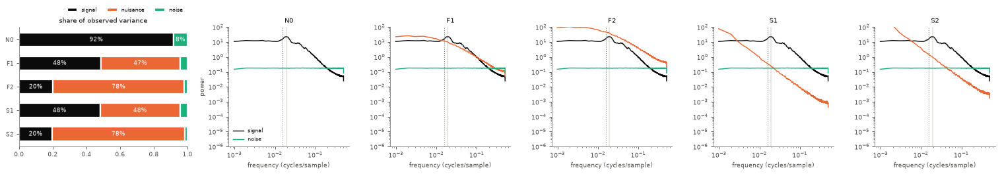

In [6]:
from scipy.signal import welch
LONG = {c: components(c, n=16000, R=2, tag=98) for c in CONDS}
COMPC = dict(signal=INK, nuisance=ORANGE, noise=AQUA)
fig, ax = plt.subplots(1, 6, figsize=(19, 3.4), gridspec_kw=dict(width_ratios=[1.4, 1, 1, 1, 1, 1]))
share = pd.DataFrame({c: {p: LONG[c][p].var() for p in COMPC} for c in CONDS}).T
share = share.div(share.sum(1), axis=0)
left = np.zeros(len(CONDS))
for p, col in COMPC.items():
    ax[0].barh(range(len(CONDS)), share[p], left=left, color=col, height=0.6, label=p, edgecolor="white", lw=2)
    for i, (l0, w) in enumerate(zip(left, share[p])):
        if w > 0.06: ax[0].text(l0 + w / 2, i, f"{w:.0%}", ha="center", va="center", color="white", fontsize=8)
    left += share[p].to_numpy()
ax[0].set_yticks(range(len(CONDS)), CONDS); ax[0].invert_yaxis(); ax[0].set_xlim(0, 1)
ax[0].set_title("share of observed variance"); ax[0].legend(fontsize=7, loc="lower right", bbox_to_anchor=(1, 1.08), ncol=3)
for a, c in zip(ax[1:], CONDS):
    for p, col in COMPC.items():
        X = LONG[c][p]
        if X.std() == 0: continue
        f, P = welch(X, nperseg=1024, axis=1); P = P.mean(axis=(0, 2))
        a.loglog(f[1:], P[1:], color=col, lw=1.3, label=p)
    a.axvline(0.12 / (2 * np.pi), color=RULE, lw=1.5, zorder=0); a.axvline(1 / W, ls=":", color=MUTED, lw=1)
    a.set_title(c); a.set_xlabel("frequency (cycles/sample)"); a.set_ylim(1e-6, 1e2)
ax[1].set_ylabel("power"); ax[1].legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.show()

### 1e. Why the type of nuisance matters for prediction

Each point is one context–target pair: the nuisance part of the observation (mean over the context window), against
the same quantity in the target window 96 samples later. A predictor can exploit the nuisance only if the target's
nuisance is predictable from the context's.

- **Fast (F):** a shapeless cloud (r ≈ 0). Predicting the target gains nothing from the nuisance.
- **Slow (S):** the points lie on the diagonal (r ≈ 0.9). The nuisance is the easiest thing to predict.
- **Signal:** its window mean barely carries over (r ≈ 0.15). What a predictor can use from the signal is the rotation
  direction, which is a property of phase order, not of level.

The r values are printed in each panel title.

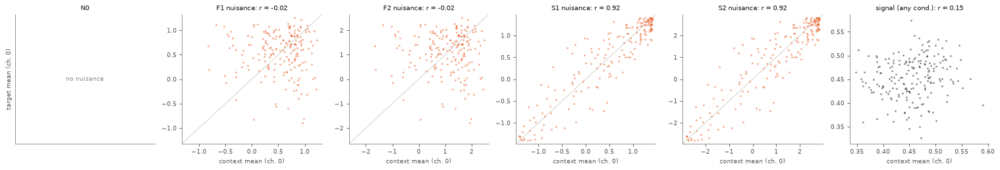

In [7]:
fig, ax = plt.subplots(1, 6, figsize=(19, 3.3))
starts = np.arange(0, 16000 - 2 * W - GAP, 2 * W + GAP)
def pair_means(X):
    ctx = np.stack([X[:, s:s + W].mean(1) for s in starts], 1); tgt = np.stack([X[:, s + W + GAP:s + 2 * W + GAP].mean(1) for s in starts], 1)
    return ctx[..., 0].ravel(), tgt[..., 0].ravel()
for a, c in zip(ax[:5], CONDS):
    if CONDITIONS[c][1] == 0:
        a.text(0.5, 0.5, "no nuisance", ha="center", va="center", transform=a.transAxes, color=MUTED); a.set_title(c); a.set_xticks([]); a.set_yticks([]); continue
    cx, tx = pair_means(LONG[c]["nuisance"])
    a.scatter(cx, tx, s=6, color=ORANGE, alpha=0.6, lw=0); lim = np.abs(np.r_[cx, tx]).max() * 1.05
    a.plot([-lim, lim], [-lim, lim], color=RULE, lw=1.5, zorder=0); a.set_xlim(-lim, lim); a.set_ylim(-lim, lim)
    a.set_title(f"{c} nuisance: r = {np.corrcoef(cx, tx)[0, 1]:.2f}"); a.set_xlabel("context mean (ch. 0)")
ax[0].set_ylabel("target mean (ch. 0)")
cx, tx = pair_means(LONG["N0"]["signal"])
ax[5].scatter(cx, tx, s=6, color=INK, alpha=0.5, lw=0); ax[5].set_title(f"signal (any cond.): r = {np.corrcoef(cx, tx)[0, 1]:.2f}")
ax[5].set_xlabel("context mean (ch. 0)")
plt.tight_layout(); plt.show()

### 1f. What the observations look like once standardised, condition by condition

This compares the per-channel standardised observation of one test series across conditions, with 1500 samples and
regime 1 shaded above. In N0 the texture is the rotation alone. F adds dense, fast speckle. S adds slowly drifting
horizontal bands, a per-channel offset that changes over thousands of samples.

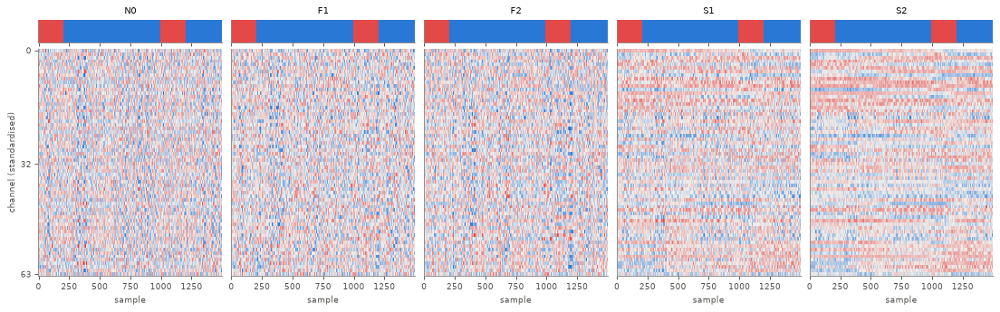

In [8]:
seg = slice(0, 1500)
fig, ax = plt.subplots(2, 5, figsize=(17, 4.6), sharex=True, gridspec_kw=dict(height_ratios=[0.1, 1], hspace=0.05, wspace=0.05))
for j, c in enumerate(CONDS):
    t = benches[c].test
    ax[0, j].imshow(t["S_s"][0, seg][None], aspect="auto", cmap=mpl.colors.ListedColormap(REG), vmin=0, vmax=1); ax[0, j].set_yticks([])
    ax[0, j].set_title(c)
    ax[1, j].imshow(t["obs"][0, seg].T, aspect="auto", cmap=DIV, vmin=-3, vmax=3)
    ax[1, j].set_xlabel("sample");  ax[1, j].set_yticks([] if j else [0, 32, 63])
ax[1, 0].set_ylabel("channel (standardised)")
plt.show()

### 1g. The regime itself

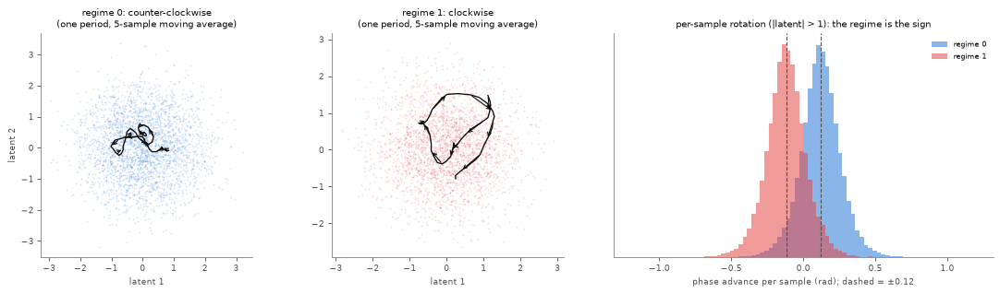

In [9]:
t = benches["N0"].test; S = t["S_s"][0]; Z = t["latent"][0]
ma = lambda x, k=5: np.stack([np.convolve(x[:, q], np.ones(k) / k, mode="valid") for q in range(2)], 1)
fig, ax = plt.subplots(1, 3, figsize=(14, 4), gridspec_kw=dict(width_ratios=[1, 1, 1.4]))
for k in (0, 1):
    i0 = next(i for i in range(0, len(S) - 300) if (S[i:i + 300] == k).all())
    z = ma(Z[i0:i0 + 60])
    turn = np.mean(z[:-1, 0] * z[1:, 1] - z[:-1, 1] * z[1:, 0])
    ax[k].plot(Z[S == k][::3, 0], Z[S == k][::3, 1], ".", color=REG[k], ms=1.5, alpha=0.15)
    ax[k].plot(z[:, 0], z[:, 1], color=INK, lw=1.2)
    for q in range(0, len(z) - 4, 5):
        ax[k].annotate("", z[q + 3], z[q], arrowprops=dict(arrowstyle="->", color=INK, lw=1))
    ax[k].set_title(f"regime {k}: {'counter-clockwise' if turn > 0 else 'clockwise'}\n(one period, 5-sample moving average)")
    ax[k].set_aspect("equal"); ax[k].set_xlabel("latent 1")
ax[0].set_ylabel("latent 2")
L2 = t["latent"]; Sa = t["S_s"]
phi = np.arctan2(L2[..., 1], L2[..., 0]); dphi = np.angle(np.exp(1j * (phi[:, 1:] - phi[:, :-1])))
ok = (np.linalg.norm(L2[:, :-1], axis=-1) > 1) & (Sa[:, 1:] == Sa[:, :-1])
bins = np.linspace(-1.2, 1.2, 81)
for k in (0, 1):
    ax[2].hist(dphi[ok & (Sa[:, 1:] == k)], bins=bins, color=REG[k], alpha=0.55, lw=0, density=True, label=f"regime {k}")
for w in (-0.12, 0.12): ax[2].axvline(w, ls="--", color=INK2, lw=1)
ax[2].set_xlabel("phase advance per sample (rad); dashed = ±0.12"); ax[2].set_yticks([]); ax[2].legend(fontsize=7.5)
ax[2].set_title("per-sample rotation (|latent| > 1): the regime is the sign")
plt.tight_layout(); plt.show()

**The timing manipulation.** Context = samples [0, 64), target = [96, 160). The nearest context and target samples
are 33 apart. Fast nuisance (tau = 16) decorrelates across the gap, while slow nuisance (tau = 2000) carries straight
through. So a predictor can use the slow nuisance and can barely use the fast one.

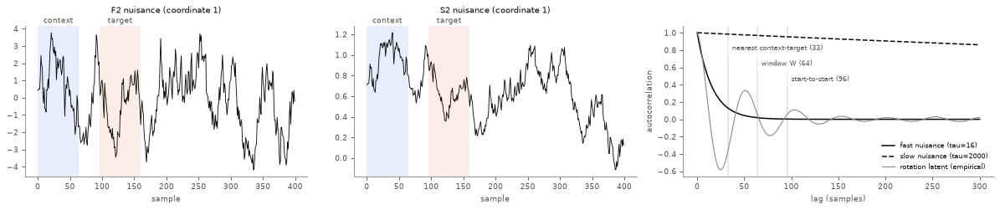

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.2), gridspec_kw=dict(width_ratios=[1, 1, 1.1]))
for a, c in zip(ax[:2], ("F2", "S2")):
    u = 2 * benches[c].test["nuisance"][0, :400, 0]
    for lo, hi, lab in ((0, W, "context"), (W + GAP, 2 * W + GAP, "target")):
        a.axvspan(lo, hi, color=BLUE if lab == "context" else ORANGE, alpha=0.12, lw=0)
        a.text((lo + hi) / 2, 1.02, lab, transform=a.get_xaxis_transform(), ha="center", color=INK2)
    a.plot(u, color=INK, lw=0.8); a.set_title(f"{c} nuisance (coordinate 1)", pad=14); a.set_xlabel("sample")
lag = np.arange(0, 301)
for sp, ls in (("fast", "-"), ("slow", "--")):
    ax[2].plot(lag, np.exp(-lag / TAU[sp]), ls, color=INK, lw=1.4, label=f"{sp} nuisance (tau={TAU[sp]})")
lat = benches["N0"].test["latent"][:, :, 0]; lat = (lat - lat.mean()) / lat.std()
ac = [np.mean(lat[:, :lat.shape[1] - l] * lat[:, l:]) for l in lag]
ax[2].plot(lag, ac, color=MUTED, lw=1, label="rotation latent (empirical)")
for x, yl, lab in ((33, 0.80, "nearest context-target (33)"), (W, 0.62, "window W (64)"), (W + GAP, 0.44, "start-to-start (96)")):
    ax[2].axvline(x, color=RULE, lw=1.5, zorder=0); ax[2].text(x + 4, yl, lab, color=INK2, fontsize=7, backgroundcolor="white")
ax[2].set_xlabel("lag (samples)"); ax[2].set_ylabel("autocorrelation"); ax[2].legend(loc="lower right", fontsize=7)
plt.tight_layout(); plt.show()

## 2. Results for every variation

All gates passed, so these verdicts are confirmatory. Rows marked `secondary`, `exploratory`, `info` or `reported`
decide nothing. Every metric recorded for the 110 confirmatory rows (5 conditions × (6 learners × 3 seeds + 4
controls)) is shown below.

In [11]:
v = pd.read_csv(os.path.join(L, "verdicts.csv"))
with pd.option_context("display.max_colwidth", 160, "display.width", 250, "display.max_rows", 100):
    display(v)

,test,verdict,numbers
0,gate: complete confirmatory protocol,pass,"missing=0, duplicates=False, finite=True, budget=True, protocol=True, fresh eval series=True"
1,gate: oracle HMM acc >= 0.95 everywhere,pass,"N0 0.959, F1 0.959, F2 0.959, S1 0.959, S2 0.959"
2,gate: some trained learner has probe >= 0.9 on N0,pass,best mean linear probe 0.981 (jepa_shared)
3,"gate: no collapse (eff_rank > 2, final loss < loss at 1k; excl. pre-declared cpc)",pass,-
4,"reported: pre-declared failed-to-train methods (cpc), collapse criterion",info,0/15 runs fail it: -
5,control F1: family probe_mlp_single - untrained (0.609) >= 0.05,info,"pred +0.352: keeps regime, recon +0.330: keeps regime"
6,control F1: family probe - untrained (0.605) >= 0.05,info,"pred +0.369: keeps regime, recon -0.049: does not meet retention criterion"
7,control F2: family probe_mlp_single - untrained (0.548) >= 0.05,info,"pred +0.420: keeps regime, recon +0.399: keeps regime"
8,control F2: family probe - untrained (0.540) >= 0.05,info,"pred +0.433: keeps regime, recon +0.046: does not meet retention criterion"
9,control N0: family probe_mlp_single - untrained (0.714) >= 0.05,info,"pred +0.249: keeps regime, recon +0.243: keeps regime"


### 2a. Every metric as a heatmap (learner × condition, mean over seeds)

Colour scales:
- accuracies and probes run from 0.5 (chance) to 1;
- change-point scores run from 0 to 1;
- R² uses a diverging scale centred on 0;
- the other metrics use their own range.

Controls have one row (seed 0). Groups:
- **retention:** regime probes
- **nuisance:** nuisance accessibility and sensitivity
- **clustering:** regime recovery without labels
- **change points:** HMM and GMM change-point scores
- **identifiability:** exploratory
- **geometry and training:** effective rank, loss drop, parameter counts

One secondary result is worth noting (descriptive; decides nothing). The *fixed whitened* HMM, without persistence
selection, recovers the regime on S2 from AE/VAE features (0.97) but not from the JEPAs (≈ 0.53). So the S-condition
failure of the reconstruction learners under the primary HMM comes from its persistence-based model selection, not
from their features. The fixed fit does not help the JEPAs. It also fails on `raw_lagcov` and the oracle (≈ 0.5),
where the primary detector succeeds, so neither detector dominates.

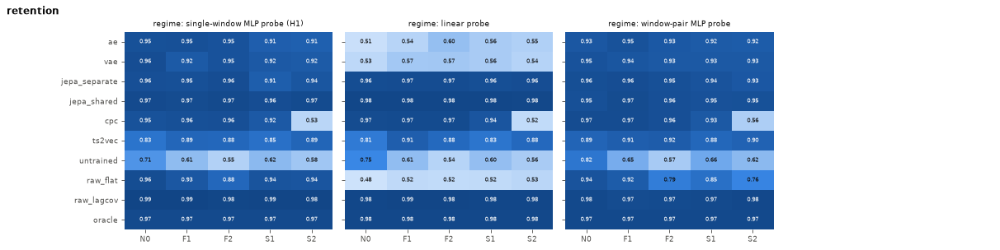

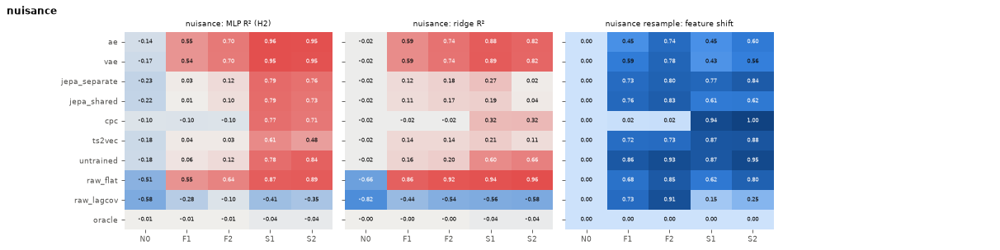

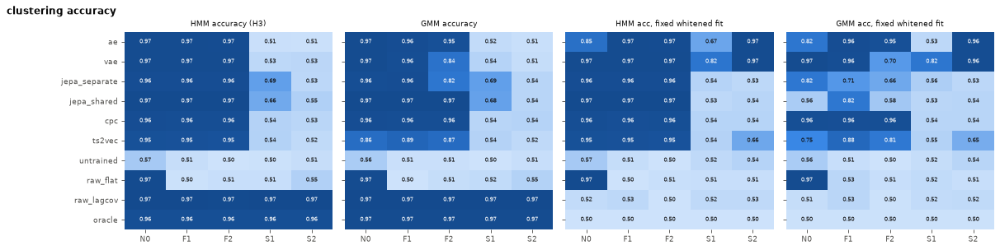

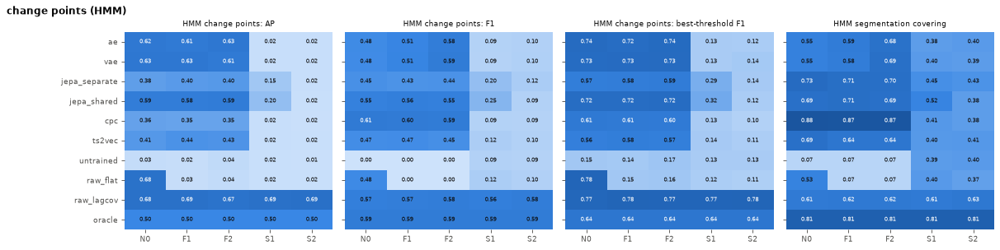

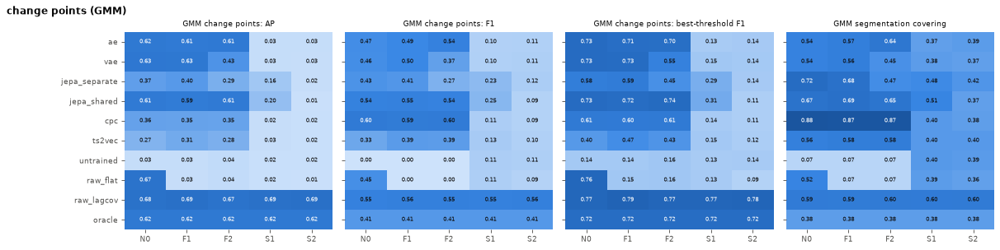

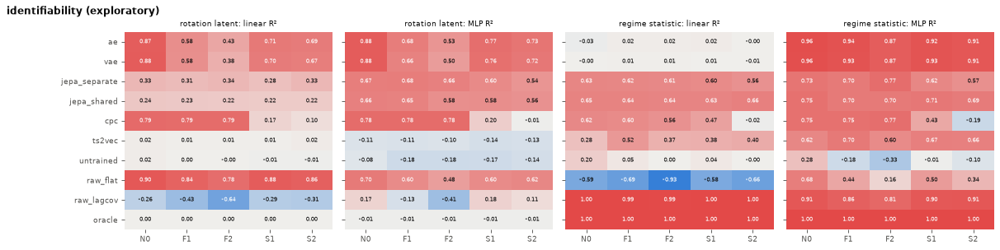

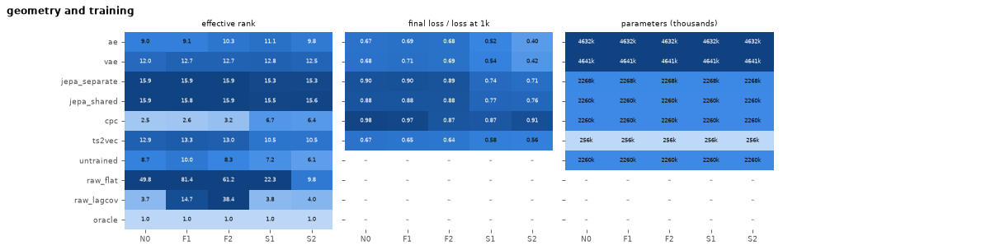

In [12]:
SPEC = {  # metric: (title, colour, lo, hi, fmt)
    "probe_mlp_single": ("regime: single-window MLP probe (H1)", "seq", 0.5, 1, ".2f"),
    "probe": ("regime: linear probe", "seq", 0.5, 1, ".2f"),
    "probe_mlp_pair": ("regime: window-pair MLP probe", "seq", 0.5, 1, ".2f"),
    "nuis_mlp_r2": ("nuisance: MLP R² (H2)", "div", -1, 1, ".2f"),
    "nuis_r2": ("nuisance: ridge R²", "div", -1, 1, ".2f"),
    "nuis_paired_distance": ("nuisance resample: feature shift", "seq", 0, None, ".2f"),
    "hmm": ("HMM accuracy (H3)", "seq", 0.5, 1, ".2f"), "gmm": ("GMM accuracy", "seq", 0.5, 1, ".2f"),
    "hmm_fixed_acc": ("HMM acc, fixed whitened fit", "seq", 0.5, 1, ".2f"), "gmm_fixed_acc": ("GMM acc, fixed whitened fit", "seq", 0.5, 1, ".2f"),
    "hmm_cp_ap": ("HMM change points: AP", "seq", 0, 1, ".2f"), "hmm_cp_f1": ("HMM change points: F1", "seq", 0, 1, ".2f"),
    "hmm_cp_f1_best": ("HMM change points: best-threshold F1", "seq", 0, 1, ".2f"), "hmm_cp_covering": ("HMM segmentation covering", "seq", 0, 1, ".2f"),
    "gmm_cp_ap": ("GMM change points: AP", "seq", 0, 1, ".2f"), "gmm_cp_f1": ("GMM change points: F1", "seq", 0, 1, ".2f"),
    "gmm_cp_f1_best": ("GMM change points: best-threshold F1", "seq", 0, 1, ".2f"), "gmm_cp_covering": ("GMM segmentation covering", "seq", 0, 1, ".2f"),
    "lat_lin": ("rotation latent: linear R²", "div", -1, 1, ".2f"), "lat_mlp": ("rotation latent: MLP R²", "div", -1, 1, ".2f"),
    "stat_lin": ("regime statistic: linear R²", "div", -1, 1, ".2f"), "stat_mlp": ("regime statistic: MLP R²", "div", -1, 1, ".2f"),
    "eff_rank": ("effective rank", "seq", 0, 16, ".1f"), "loss_drop": ("final loss / loss at 1k", "seq", 0, 1, ".2f"),
    "parameters_total": ("parameters (thousands)", "seq", 0, None, "k"),
}
GROUPS = {"retention": ["probe_mlp_single", "probe", "probe_mlp_pair"],
          "nuisance": ["nuis_mlp_r2", "nuis_r2", "nuis_paired_distance"],
          "clustering accuracy": ["hmm", "gmm", "hmm_fixed_acc", "gmm_fixed_acc"],
          "change points (HMM)": ["hmm_cp_ap", "hmm_cp_f1", "hmm_cp_f1_best", "hmm_cp_covering"],
          "change points (GMM)": ["gmm_cp_ap", "gmm_cp_f1", "gmm_cp_f1_best", "gmm_cp_covering"],
          "identifiability (exploratory)": ["lat_lin", "lat_mlp", "stat_lin", "stat_mlp"],
          "geometry and training": ["eff_rank", "loss_drop", "parameters_total"]}
mean = df.groupby(["learner", "cond"]).mean(numeric_only=True)
sd = df.groupby(["learner", "cond"]).std(numeric_only=True)
def heat(a, m, show_y):
    title, kind, lo, hi, fmt = SPEC[m]
    T = mean[m].unstack()[CONDS].reindex(ORDER)
    if hi is None: hi = np.nanmax(T.values)
    a.imshow(np.ma.masked_invalid(T.values), cmap=SEQ if kind == "seq" else DIV, vmin=lo, vmax=hi, aspect="auto")
    for (i, j), val in np.ndenumerate(T.values):
        if not np.isfinite(val): a.text(j, i, "–", ha="center", va="center", color=MUTED, fontsize=7); continue
        dark = abs(val) > 0.6 * max(abs(lo), abs(hi)) if kind == "div" else (np.clip(val, lo, hi) - lo) / (hi - lo) > 0.6
        txt = f"{val / 1000:.0f}k" if fmt == "k" else format(val, fmt)
        a.text(j, i, txt, ha="center", va="center", fontsize=6.5, color="white" if dark else INK)
    a.set_xticks(range(5), CONDS); a.set_title(title, fontsize=8.5)
    a.set_yticks(range(len(ORDER)), ORDER if show_y else [])
    for sp in a.spines.values(): sp.set_visible(False)
for g, ms in GROUPS.items():
    fig, axes = plt.subplots(1, 4, figsize=(17, 3.9), gridspec_kw=dict(wspace=0.06))
    for k, a in enumerate(axes):
        if k < len(ms): heat(a, ms[k], k == 0)
        else: a.axis("off")
    fig.suptitle(g, x=0.02, ha="left", fontsize=11, fontweight="bold"); plt.show()

### 2b. Every seed, every learner, every condition

Dots are the individual runs (3 seeds per trained learner; 1 for controls) and the bar is their mean. This shows
the seed-to-seed spread behind every mean above.

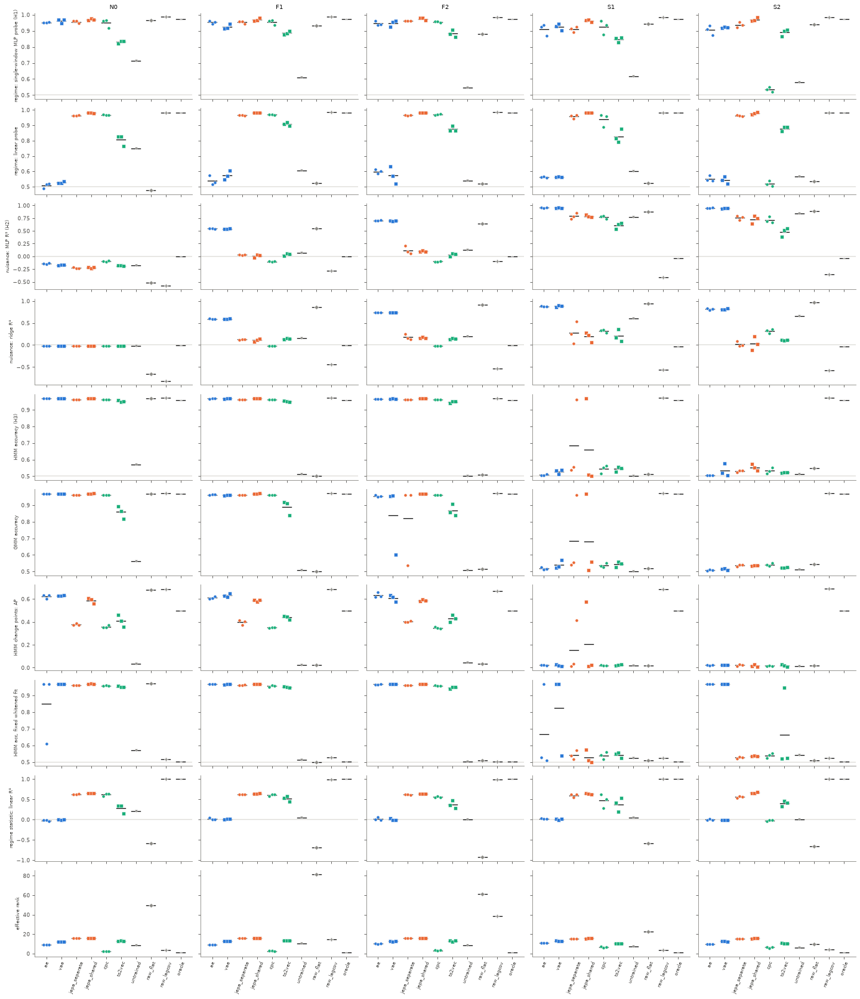

In [13]:
STRIP = ["probe_mlp_single", "probe", "nuis_mlp_r2", "nuis_r2", "hmm", "gmm", "hmm_cp_ap", "hmm_fixed_acc", "stat_lin", "eff_rank"]
fig, axes = plt.subplots(len(STRIP), 5, figsize=(18, 2.1 * len(STRIP)), sharex=True, sharey="row")
for i, m in enumerate(STRIP):
    for j, c in enumerate(CONDS):
        a = axes[i, j]
        for x, key in enumerate(ORDER):
            v = df[(df.cond == c) & (df.learner == key)][m].dropna().to_numpy()
            if not len(v): continue
            jit = np.linspace(-0.18, 0.18, len(v)) if len(v) > 1 else [0]
            a.scatter(x + np.asarray(jit), v, marker=MARK[key], color=FAMC[FAMILY[key]], s=22, edgecolor="white", lw=0.5, zorder=3)
            a.plot([x - 0.3, x + 0.3], [v.mean()] * 2, color=INK, lw=1.2)
        if m in ("probe_mlp_single", "probe", "hmm", "hmm_fixed_acc"): a.axhline(0.5, color=RULE, lw=1.5, zorder=0)
        if m in ("nuis_mlp_r2", "nuis_r2", "stat_lin"): a.axhline(0, color=RULE, lw=1.5, zorder=0)
        if i == 0: a.set_title(c)
        if j == 0: a.set_ylabel(SPEC[m][0], fontsize=7.5)
for a in axes[-1]: a.set_xticks(range(len(ORDER)), ORDER, rotation=70, fontsize=7.5)
plt.tight_layout(); plt.show()

### 2c. Paired family effects (prediction − reconstruction) for every metric and condition

Gray dots are the three per-seed paired differences. Black is the mean with its 95% bootstrap CI over seeds. Dashed
lines mark the pre-registered decision bands (< 0.05 refutes; ≥ 0.10 with CI > 0 supports), drawn only where they
decide a hypothesis (H1 and H3b on F2). Every other cell is descriptive.

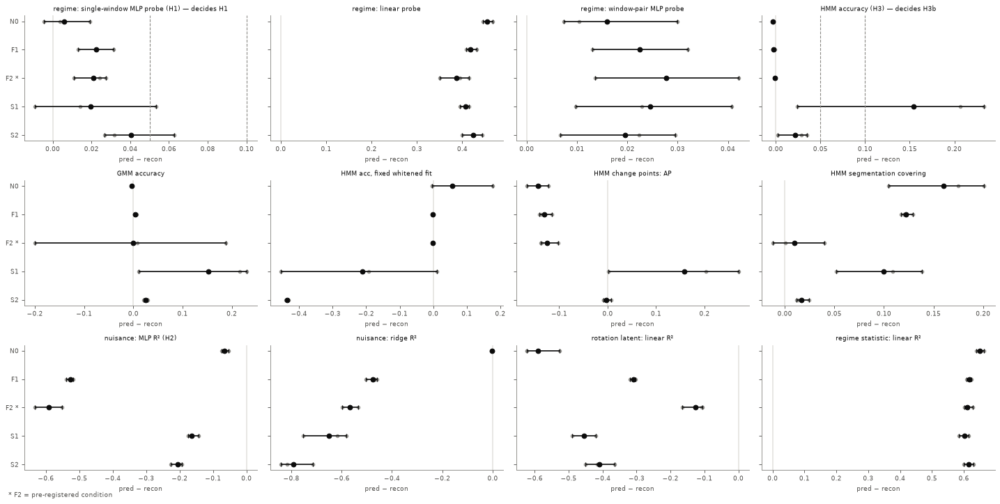

In [14]:
def fam_seed(c, ls, m):
    return df[(df.cond == c) & df.learner.isin(ls)].groupby("seed")[m].mean().reindex([0, 1, 2]).to_numpy()
EFF = ["probe_mlp_single", "probe", "probe_mlp_pair", "hmm", "gmm", "hmm_fixed_acc", "hmm_cp_ap", "hmm_cp_covering",
       "nuis_mlp_r2", "nuis_r2", "lat_lin", "stat_lin"]
fig, axes = plt.subplots(3, 4, figsize=(18, 9), sharey=True)
for a, m in zip(axes.ravel(), EFF):
    for i, c in enumerate(CONDS):
        p, r = fam_seed(c, PRED, m), fam_seed(c, RECON, m)
        d, ci = _boot_diff(p, r)
        a.plot(p - r, [i] * 3, "o", color=MUTED, ms=4, alpha=0.8)
        a.errorbar(d, i, xerr=[[d - ci[0]], [ci[1] - d]], fmt="o", color=INK, ms=6, capsize=3, lw=1.5)
    if m in ("probe_mlp_single", "hmm"):
        for x in (0.05, 0.10): a.axvline(x, ls="--", color=MUTED, lw=1)
    a.axvline(0, color=RULE, lw=1.5, zorder=0)
    a.set_title(SPEC[m][0] + (" — decides H1" if m == "probe_mlp_single" else " — decides H3b" if m == "hmm" else ""), fontsize=8.5)
    a.set_xlabel("pred − recon")
for a in axes[:, 0]: a.set_yticks(range(5), [c + (" *" if c == "F2" else "") for c in CONDS])
axes[0, 0].invert_yaxis()
fig.text(0.01, 0.005, "* F2 = pre-registered condition", color=INK2, fontsize=8)
plt.tight_layout(); plt.show()

### 2d. Geometry: is the information *linearly* accessible?

 Each point is one learner in one condition (seed mean).
Points on the diagonal are as readable linearly as nonlinearly. Points far below it hold the information in a
nonlinear form.

- **Left (regime):** the JEPAs sit on the diagonal, while AE/VAE sit at linear ≈ 0.55 against MLP ≈ 0.95.
- **Middle (instantaneous latent):** the pattern reverses.
- **Right (regime statistic):** the JEPAs are linear, AE/VAE nonlinear.

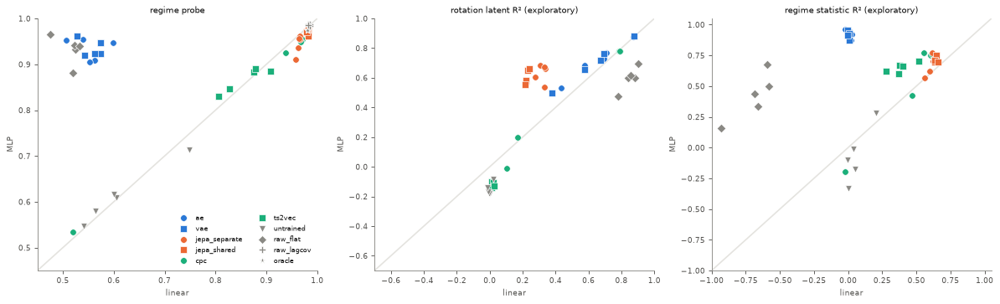

In [15]:
pairs = [("probe", "probe_mlp_single", "regime probe", (0.45, 1.0)),
         ("lat_lin", "lat_mlp", "rotation latent R² (exploratory)", (-0.7, 1.0)),
         ("stat_lin", "stat_mlp", "regime statistic R² (exploratory)", (-1.0, 1.05))]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for a, (x, y, title, lim) in zip(axes, pairs):
    a.plot(lim, lim, color=RULE, lw=1.5, zorder=0)
    for (key, c), r in mean.iterrows():
        if key in ("raw_lagcov", "oracle") and x != "probe":
            continue
        a.scatter(np.clip(r[x], *lim), np.clip(r[y], *lim), marker=MARK[key], color=FAMC[FAMILY[key]], s=46,
                  edgecolor="white", lw=0.6, zorder=3)
    a.set_xlim(lim); a.set_ylim(lim); a.set_xlabel("linear"); a.set_ylabel("MLP"); a.set_title(title)
axes[0].legend(handles=learner_handles(), fontsize=7, loc="lower right", ncol=2)
plt.tight_layout(); plt.show()

### 2e. Mechanism (exploratory association)

 Nuisance accessibility against HMM accuracy, one point per run. On F the
JEPAs sit to the left (nuisance dropped), yet AE/VAE cluster just as well with the nuisance kept. On S everyone
fails to cluster.

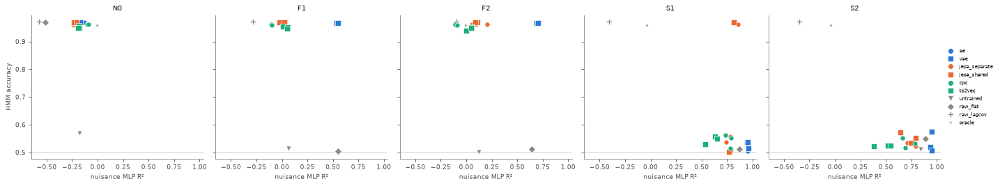

In [16]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.4), sharey=True, sharex=True)
for a, c in zip(axes, CONDS):
    for r in df[(df.cond == c) & df.learner.isin(ORDER)].itertuples():
        a.scatter(r.nuis_mlp_r2, r.hmm, marker=MARK[r.learner], color=FAMC[r.family], s=40, edgecolor="white", lw=0.6)
    a.axhline(0.5, color=RULE, lw=1.5, zorder=0); a.set_title(c); a.set_xlabel("nuisance MLP R²")
axes[0].set_ylabel("HMM accuracy"); axes[-1].legend(handles=learner_handles(), fontsize=6.5, loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout(); plt.show()

### 2f. Dose response for every trained learner

Each metric is plotted against nuisance amplitude sigma_n. Solid is fast nuisance and dashed is slow; sigma_n = 0 is
N0, shared by both. Thin lines are seeds and thick lines their mean.

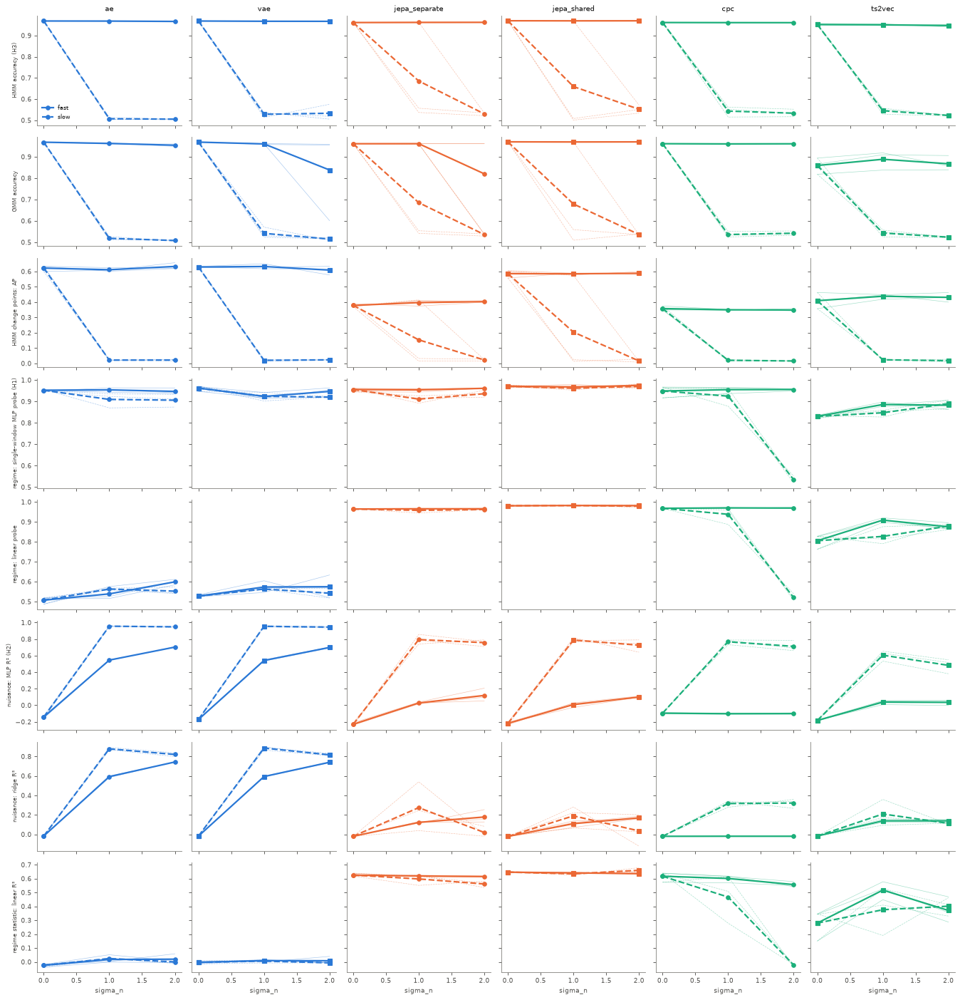

In [17]:
rows = ["hmm", "gmm", "hmm_cp_ap", "probe_mlp_single", "probe", "nuis_mlp_r2", "nuis_r2", "stat_lin"]
fig, axes = plt.subplots(len(rows), 6, figsize=(17, 2.2 * len(rows)), sharex=True, sharey="row")
for j, l in enumerate(TRAINED):
    col = FAMC[FAMILY[l]]
    for i, m in enumerate(rows):
        a = axes[i, j]
        for sp, ls in (("fast", "-"), ("slow", "--")):
            sub = df[(df.learner == l) & ((df.speed == sp) | (df.cond == "N0"))]
            for s, g in sub.groupby("seed"):
                g = g.sort_values("sigma_n"); a.plot(g.sigma_n, g[m], ls, color=col, lw=0.6, alpha=0.4)
            g = sub.groupby("sigma_n")[m].mean(); a.plot(g.index, g.values, ls, color=col, lw=2, marker=MARK[l], ms=5, label=sp)
        if j == 0: a.set_ylabel(SPEC[m][0], fontsize=7.5)
        if i == 0: a.set_title(l)
        if i == len(rows) - 1: a.set_xlabel("sigma_n")
axes[0, 0].legend(fontsize=7)
plt.tight_layout(); plt.show()

### 2g. Full numeric tables

The tables give mean ± sd over seeds for every metric, by group. After them comes the complete per-run table, all
110 rows and every column.

In [18]:
def table(ms):
    out = {}
    for m in ms:
        mu, s = mean[m].unstack()[CONDS].reindex(ORDER), sd[m].unstack()[CONDS].reindex(ORDER)
        fmt = (lambda v: f"{v / 1000:.0f}k") if SPEC[m][4] == "k" else (lambda v: format(v, SPEC[m][4]))
        out[m] = mu.map(lambda v: "–" if not np.isfinite(v) else fmt(v)) + s.map(lambda v: "" if not np.isfinite(v) else " ± " + format(v, ".2f" if SPEC[m][4] != "k" else ".0f"))
    return pd.concat(out, axis=1)
with pd.option_context("display.max_columns", 200, "display.width", 300):
    for g, ms in GROUPS.items():
        print("\n" + g.upper()); display(table(ms))


RETENTION


probe_mlp_single                                                            probe                                                     probe_mlp_pair                                                    
cond                        N0           F1           F2           S1           S2           N0           F1           F2           S1           S2             N0           F1           F2           S1           S2
learner                                                                                                                                                                                                               
ae                 0.95 ± 0.00  0.95 ± 0.01  0.95 ± 0.01  0.91 ± 0.03  0.91 ± 0.03  0.51 ± 0.02  0.54 ± 0.03  0.60 ± 0.01  0.56 ± 0.00  0.55 ± 0.02    0.93 ± 0.01  0.95 ± 0.01  0.93 ± 0.01  0.92 ± 0.02  0.92 ± 0.02
vae                0.96 ± 0.01  0.92 ± 0.02  0.95 ± 0.02  0.92 ± 0.02  0.92 ± 0.00  0.53 ± 0.01  0.57 ± 0.03  0.57 ± 0.06  0.56 ± 0.00  0.54 ± 0.02    0.95 ± 0.01  0.94 ± 0.00  0.93 ± 0.01  0.93 ± 0.01  0.93 ± 0.01
jepa_separate      0.96 ± 0.01  0.95 ± 0.01  0.96 ± 0.00  0.91 ± 0.02  0.94 ± 0.02  0.96 ± 0.00  0.97 ± 0.00  0.97 ± 0.00  0.96 ± 0.01  0.96 ± 0.00    0.96 ± 0.01  0.96 ± 0.00  0.95 ± 0.01  0.94 ± 0.00  0.93 ± 0.01
jepa_shared        0.97 ± 0.00  0.97 ± 0.01  0.97 ± 0.01  0.96 ± 0.01  0.97 ± 0.01  0.98 ± 0.00  0.98 ± 0.00  0.98 ± 0.00  0.98 ± 0.00  0.98 ± 0.01    0.95 ± 0.02  0.97 ± 0.01  0.96 ± 0.01  0.95 ± 0.02  0.95 ± 0.01
cpc                0.95 ± 0.03  0.96 ± 0.02  0.96 ± 0.01  0.92 ± 0.04  0.53 ± 0.02  0.97 ± 0.00  0.97 ± 0.00  0.97 ± 0.00  0.94 ± 0.04  0.52 ± 0.02    0.97 ± 0.00  0.97 ± 0.00  0.96 ± 0.01  0.93 ± 0.04  0.56 ± 0.01
ts2vec             0.83 ± 0.01  0.89 ± 0.01  0.88 ± 0.02  0.85 ± 0.02  0.89 ± 0.02  0.81 ± 0.04  0.91 ± 0.01  0.88 ± 0.02  0.83 ± 0.04  0.88 ± 0.01    0.89 ± 0.00  0.91 ± 0.02  0.92 ± 0.01  0.88 ± 0.02  0.90 ± 0.02
untrained                 0.71         0.61         0.55         0.62         0.58         0.75         0.61         0.54         0.60         0.56           0.82         0.65         0.57         0.66         0.62
raw_flat                  0.96         0.93         0.88         0.94         0.94         0.48         0.52         0.52         0.52         0.53           0.94         0.92         0.79         0.85         0.76
raw_lagcov                0.99         0.99         0.98         0.99         0.98         0.98         0.99         0.98         0.98         0.98           0.98         0.97         0.97         0.97         0.98
oracle                    0.97         0.97         0.97         0.97         0.97         0.98         0.98         0.98         0.98         0.98           0.97         0.97         0.97         0.97         0.97


NUISANCE


nuis_mlp_r2                                                             nuis_r2                                                       nuis_paired_distance                                                    
cond                     N0            F1            F2           S1           S2            N0            F1            F2           S1           S2                   N0           F1           F2           S1           S2
learner                                                                                                                                                                                                                       
ae             -0.14 ± 0.01   0.55 ± 0.00   0.70 ± 0.00  0.96 ± 0.00  0.95 ± 0.01  -0.02 ± 0.00   0.59 ± 0.01   0.74 ± 0.00  0.88 ± 0.01  0.82 ± 0.02          0.00 ± 0.00  0.45 ± 0.01  0.74 ± 0.01  0.45 ± 0.01  0.60 ± 0.01
vae            -0.17 ± 0.00   0.54 ± 0.01   0.70 ± 0.01  0.95 ± 0.01  0.95 ± 0.01  -0.02 ± 0.00   0.59 ± 0.00   0.74 ± 0.00  0.89 ± 0.02  0.82 ± 0.01          0.00 ± 0.00  0.59 ± 0.00  0.78 ± 0.01  0.43 ± 0.01  0.56 ± 0.00
jepa_separate  -0.23 ± 0.02   0.03 ± 0.01   0.12 ± 0.08  0.79 ± 0.06  0.76 ± 0.04  -0.02 ± 0.00   0.12 ± 0.01   0.18 ± 0.07  0.27 ± 0.25  0.02 ± 0.06          0.00 ± 0.00  0.73 ± 0.01  0.80 ± 0.02  0.77 ± 0.02  0.84 ± 0.01
jepa_shared    -0.22 ± 0.02   0.01 ± 0.03   0.10 ± 0.01  0.79 ± 0.02  0.73 ± 0.08  -0.02 ± 0.00   0.11 ± 0.03   0.17 ± 0.01  0.19 ± 0.11  0.04 ± 0.16          0.00 ± 0.00  0.76 ± 0.01  0.83 ± 0.01  0.61 ± 0.01  0.62 ± 0.01
cpc            -0.10 ± 0.01  -0.10 ± 0.01  -0.10 ± 0.01  0.77 ± 0.03  0.71 ± 0.06  -0.02 ± 0.00  -0.02 ± 0.00  -0.02 ± 0.00  0.32 ± 0.03  0.32 ± 0.05          0.00 ± 0.00  0.02 ± 0.00  0.02 ± 0.00  0.94 ± 0.04  1.00 ± 0.01
ts2vec         -0.18 ± 0.01   0.04 ± 0.03   0.03 ± 0.03  0.61 ± 0.06  0.48 ± 0.09  -0.02 ± 0.00   0.14 ± 0.02   0.14 ± 0.01  0.21 ± 0.14  0.11 ± 0.01          0.00 ± 0.00  0.72 ± 0.01  0.73 ± 0.02  0.87 ± 0.06  0.88 ± 0.04
untrained             -0.18          0.06          0.12         0.78         0.84         -0.02          0.16          0.20         0.60         0.66                 0.00         0.86         0.93         0.87         0.95
raw_flat              -0.51          0.55          0.64         0.87         0.89         -0.66          0.86          0.92         0.94         0.96                 0.00         0.68         0.85         0.62         0.80
raw_lagcov            -0.58         -0.28         -0.10        -0.41        -0.35         -0.82         -0.44         -0.54        -0.56        -0.58                 0.00         0.73         0.91         0.15         0.25
oracle                -0.01         -0.01         -0.01        -0.04        -0.04         -0.00         -0.00         -0.00        -0.04        -0.04                 0.00         0.00         0.00         0.00         0.00


CLUSTERING ACCURACY


...

gmm_cp_ap                                                        gmm_cp_f1                                                     gmm_cp_f1_best                                                     gmm_cp_covering                                                    
cond                    N0           F1           F2           S1           S2           N0           F1           F2           S1           S2             N0           F1           F2           S1           S2              N0           F1           F2           S1           S2
learner                                                                                                                                                                                                                                                                               
ae             0.62 ± 0.02  0.61 ± 0.02  0.61 ± 0.02  0.03 ± 0.01  0.03 ± 0.01  0.47 ± 0.02  0.49 ± 0.01  0.54 ± 0.00  0.10 ± 0.01  0.11 ± 0.02    0.73 ± 0.02  0.71 ± 0.01  0.70 ± 0.01  0.13 ± 0.01  0.14 ± 0.02     0.54 ± 0.01  0.57 ± 0.00  0.64 ± 0.01  0.37 ± 0.01  0.39 ± 0.01
vae            0.63 ± 0.01  0.63 ± 0.02  0.43 ± 0.32  0.03 ± 0.01  0.03 ± 0.00  0.46 ± 0.01  0.50 ± 0.01  0.37 ± 0.32  0.10 ± 0.01  0.11 ± 0.02    0.73 ± 0.01  0.73 ± 0.01  0.55 ± 0.31  0.15 ± 0.01  0.14 ± 0.01     0.54 ± 0.01  0.56 ± 0.01  0.45 ± 0.33  0.38 ± 0.01  0.37 ± 0.01
jepa_separate  0.37 ± 0.01  0.40 ± 0.01  0.29 ± 0.21  0.16 ± 0.22  0.02 ± 0.01  0.43 ± 0.06  0.41 ± 0.03  0.27 ± 0.24  0.23 ± 0.17  0.12 ± 0.00    0.58 ± 0.01  0.59 ± 0.00  0.45 ± 0.25  0.29 ± 0.25  0.14 ± 0.01     0.72 ± 0.08  0.68 ± 0.05  0.47 ± 0.34  0.48 ± 0.14  0.42 ± 0.01
jepa_shared    0.61 ± 0.01  0.59 ± 0.01  0.61 ± 0.02  0.20 ± 0.32  0.01 ± 0.01  0.54 ± 0.01  0.55 ± 0.01  0.54 ± 0.02  0.25 ± 0.26  0.09 ± 0.04    0.73 ± 0.01  0.72 ± 0.02  0.74 ± 0.01  0.31 ± 0.35  0.11 ± 0.03     0.67 ± 0.00  0.69 ± 0.02  0.65 ± 0.04  0.51 ± 0.16  0.37 ± 0.01
cpc            0.36 ± 0.01  0.35 ± 0.00  0.35 ± 0.01  0.02 ± 0.01  0.02 ± 0.00  0.60 ± 0.00  0.59 ± 0.01  0.60 ± 0.01  0.11 ± 0.02  0.09 ± 0.02    0.61 ± 0.00  0.60 ± 0.00  0.61 ± 0.01  0.14 ± 0.03  0.11 ± 0.00     0.88 ± 0.00  0.87 ± 0.02  0.87 ± 0.01  0.40 ± 0.03  0.38 ± 0.01
ts2vec         0.27 ± 0.13  0.31 ± 0.12  0.28 ± 0.09  0.03 ± 0.01  0.02 ± 0.01  0.33 ± 0.14  0.39 ± 0.06  0.39 ± 0.04  0.13 ± 0.02  0.10 ± 0.01    0.40 ± 0.09  0.47 ± 0.09  0.43 ± 0.07  0.15 ± 0.02  0.12 ± 0.01     0.56 ± 0.12  0.58 ± 0.02  0.58 ± 0.02  0.40 ± 0.05  0.40 ± 0.01
untrained             0.03         0.03         0.04         0.02         0.02         0.00         0.00         0.00         0.11         0.11           0.14         0.14         0.16         0.13         0.14            0.07         0.07         0.07         0.40         0.39
raw_flat              0.67         0.03         0.04         0.02         0.01         0.45         0.00         0.00         0.11         0.09           0.76         0.15         0.16         0.13         0.09            0.52         0.07         0.07         0.39         0.36
raw_lagcov            0.68         0.69         0.67         0.69         0.69         0.55         0.56         0.55         0.55         0.56           0.77         0.79         0.77         0.77         0.78            0.59         0.59         0.60         0.60         0.60
oracle                0.62         0.62         0.62         0.62         0.62         0.41         0.41         0.41         0.41         0.41           0.72         0.72         0.72         0.72         0.72            0.38         0.38         0.38         0.38         0.38


IDENTIFIABILITY (EXPLORATORY)


lat_lin                                                           lat_mlp                                                              stat_lin                                                          stat_mlp                                                     
cond                    N0           F1           F2           S1           S2            N0            F1            F2            S1            S2            N0           F1           F2           S1            S2           N0           F1           F2           S1            S2
learner                                                                                                                                                                                                                                                                                  
ae             0.87 ± 0.01  0.58 ± 0.01  0.43 ± 0.04  0.71 ± 0.01  0.69 ± 0.02   0.88 ± 0.00   0.68 ± 0.01   0.53 ± 0.02   0.77 ± 0.01   0.73 ± 0.01  -0.03 ± 0.01  0.02 ± 0.03  0.02 ± 0.03  0.02 ± 0.00  -0.00 ± 0.02  0.96 ± 0.00  0.94 ± 0.00  0.87 ± 0.00  0.92 ± 0.01   0.91 ± 0.01
vae            0.88 ± 0.00  0.58 ± 0.01  0.38 ± 0.03  0.70 ± 0.03  0.67 ± 0.01   0.88 ± 0.00   0.66 ± 0.02   0.50 ± 0.00   0.76 ± 0.01   0.72 ± 0.00  -0.00 ± 0.01  0.01 ± 0.01  0.01 ± 0.03  0.01 ± 0.01  -0.01 ± 0.00  0.96 ± 0.00  0.93 ± 0.00  0.87 ± 0.01  0.93 ± 0.00   0.91 ± 0.00
jepa_separate  0.33 ± 0.11  0.31 ± 0.02  0.34 ± 0.10  0.28 ± 0.07  0.33 ± 0.08   0.67 ± 0.02   0.68 ± 0.00   0.66 ± 0.01   0.60 ± 0.02   0.54 ± 0.07   0.63 ± 0.01  0.62 ± 0.01  0.61 ± 0.00  0.60 ± 0.04   0.56 ± 0.02  0.73 ± 0.01  0.70 ± 0.04  0.77 ± 0.01  0.62 ± 0.02   0.57 ± 0.02
jepa_shared    0.24 ± 0.01  0.23 ± 0.00  0.22 ± 0.01  0.22 ± 0.03  0.22 ± 0.01   0.66 ± 0.01   0.65 ± 0.01   0.58 ± 0.07   0.58 ± 0.03   0.56 ± 0.02   0.65 ± 0.00  0.64 ± 0.01  0.64 ± 0.01  0.63 ± 0.01   0.66 ± 0.02  0.75 ± 0.02  0.70 ± 0.02  0.70 ± 0.05  0.71 ± 0.06   0.69 ± 0.01
cpc            0.79 ± 0.00  0.79 ± 0.00  0.79 ± 0.00  0.17 ± 0.06  0.10 ± 0.10   0.78 ± 0.00   0.78 ± 0.00   0.78 ± 0.00   0.20 ± 0.10  -0.01 ± 0.13   0.62 ± 0.04  0.60 ± 0.03  0.56 ± 0.02  0.47 ± 0.17  -0.02 ± 0.01  0.75 ± 0.00  0.75 ± 0.00  0.77 ± 0.01  0.43 ± 0.13  -0.19 ± 0.08
ts2vec         0.02 ± 0.01  0.01 ± 0.01  0.01 ± 0.01  0.01 ± 0.01  0.02 ± 0.01  -0.11 ± 0.03  -0.11 ± 0.00  -0.10 ± 0.01  -0.14 ± 0.02  -0.13 ± 0.02   0.28 ± 0.11  0.52 ± 0.07  0.37 ± 0.09  0.38 ± 0.17   0.40 ± 0.07  0.62 ± 0.04  0.70 ± 0.02  0.60 ± 0.07  0.67 ± 0.06   0.66 ± 0.06
untrained             0.02         0.00        -0.00        -0.01        -0.01         -0.08         -0.18         -0.18         -0.17         -0.14          0.20         0.05         0.00         0.04         -0.00         0.28        -0.18        -0.33        -0.01         -0.10
raw_flat              0.90         0.84         0.78         0.88         0.86          0.70          0.60          0.48          0.60          0.62         -0.59        -0.69        -0.93        -0.58         -0.66         0.68         0.44         0.16         0.50          0.34
raw_lagcov           -0.26        -0.43        -0.64        -0.29        -0.31          0.17         -0.13         -0.41          0.18          0.11          1.00         0.99         0.99         1.00          1.00         0.91         0.86         0.81         0.90          0.91
oracle                0.00         0.00         0.00         0.00         0.00         -0.01         -0.01         -0.01         -0.01         -0.01          1.00         1.00         1.00         1.00          1.00         1.00         1.00         1.00         1.00          1.00


GEOMETRY AND TRAINING


eff_rank                                                        loss_drop                                                     parameters_total                                            
cond                    N0           F1           F2           S1           S2           N0           F1           F2           S1           S2               N0         F1         F2         S1         S2
learner                                                                                                                                                                                                     
ae              9.0 ± 0.07   9.1 ± 0.06  10.3 ± 0.30  11.1 ± 0.12   9.8 ± 0.14  0.67 ± 0.00  0.69 ± 0.00  0.68 ± 0.01  0.52 ± 0.00  0.40 ± 0.01        4632k ± 0  4632k ± 0  4632k ± 0  4632k ± 0  4632k ± 0
vae            12.0 ± 0.02  12.7 ± 0.12  12.7 ± 0.36  12.8 ± 0.29  12.5 ± 0.36  0.68 ± 0.00  0.71 ± 0.01  0.69 ± 0.00  0.54 ± 0.00  0.42 ± 0.01        4641k ± 0  4641k ± 0  4641k ± 0  4641k ± 0  4641k ± 0
jepa_separate  15.9 ± 0.01  15.9 ± 0.01  15.9 ± 0.01  15.3 ± 0.13  15.3 ± 0.08  0.90 ± 0.00  0.90 ± 0.01  0.89 ± 0.01  0.74 ± 0.01  0.71 ± 0.01        2268k ± 0  2268k ± 0  2268k ± 0  2268k ± 0  2268k ± 0
jepa_shared    15.9 ± 0.02  15.8 ± 0.01  15.9 ± 0.01  15.5 ± 0.18  15.6 ± 0.15  0.88 ± 0.00  0.88 ± 0.00  0.88 ± 0.00  0.77 ± 0.01  0.76 ± 0.01        2260k ± 0  2260k ± 0  2260k ± 0  2260k ± 0  2260k ± 0
cpc             2.5 ± 0.15   2.6 ± 0.14   3.2 ± 0.35   6.7 ± 0.72   6.4 ± 0.66  0.98 ± 0.00  0.97 ± 0.00  0.87 ± 0.00  0.87 ± 0.02  0.91 ± 0.02        2260k ± 0  2260k ± 0  2260k ± 0  2260k ± 0  2260k ± 0
ts2vec         12.9 ± 0.26  13.3 ± 0.23  13.0 ± 0.58  10.5 ± 0.12  10.5 ± 0.13  0.67 ± 0.04  0.65 ± 0.03  0.64 ± 0.02  0.58 ± 0.03  0.56 ± 0.02         256k ± 0   256k ± 0   256k ± 0   256k ± 0   256k ± 0
untrained              8.7         10.0          8.3          7.2          6.1            –            –            –            –            –            2260k      2260k      2260k      2260k      2260k
raw_flat              49.8         81.4         61.2         22.3          9.8            –            –            –            –            –                –          –          –          –          –
raw_lagcov             3.7         14.7         38.4          3.8          4.0            –            –            –            –            –                –          –          –          –          –
oracle                 1.0          1.0          1.0          1.0          1.0            –            –            –            –            –                –          –          –          –          –

In [19]:
with pd.option_context("display.max_rows", 200, "display.max_columns", 100, "display.width", 400):
    cols = ["cond", "learner", "family", "seed"] + [m for ms in GROUPS.values() for m in ms] + ["backbone", "parameters_encoder", "steps", "protocol", "eval_seed"]
    pos = {k: i for i, k in enumerate(CONDS + ORDER)}
    display(df.assign(_c=df.cond.map(pos), _l=df.learner.map(pos)).sort_values(["_c", "_l", "seed"])[cols].reset_index(drop=True).round(3))

,cond,learner,family,seed,probe_mlp_single,probe,probe_mlp_pair,nuis_mlp_r2,nuis_r2,nuis_paired_distance,hmm,gmm,hmm_fixed_acc,gmm_fixed_acc,hmm_cp_ap,hmm_cp_f1,hmm_cp_f1_best,hmm_cp_covering,gmm_cp_ap,gmm_cp_f1,gmm_cp_f1_best,gmm_cp_covering,lat_lin,lat_mlp,stat_lin,stat_mlp,eff_rank,loss_drop,parameters_total,backbone,parameters_encoder,steps,protocol,eval_seed
0,N0,ae,reconstruction,0,0.949,0.487,0.939,-0.143,-0.019,0.000,0.969,0.968,0.969,0.968,0.632,0.490,0.745,0.550,0.633,0.477,0.742,0.533,0.863,0.872,-0.019,0.961,9.030,0.673,4632336.0,tcn,2259728.0,20000,audit_v2+pilot_informed_v1,20261016
1,N0,ae,reconstruction,1,0.952,0.515,0.941,-0.155,-0.016,0.000,0.968,0.968,0.609,0.528,0.600,0.466,0.715,0.551,0.598,0.449,0.712,0.536,0.879,0.878,-0.018,0.964,9.043,0.674,4632336.0,tcn,2259728.0,20000,audit_v2+pilot_informed_v1,20261016
2,N0,ae,reconstruction,2,0.955,0.519,0.921,-0.129,-0.017,0.000,0.969,0.968,0.969,0.968,0.634,0.483,0.748,0.550,0.630,0.475,0.743,0.545,0.879,0.880,-0.038,0.960,8.918,0.670,4632336.0,tcn,2259728.0,20000,audit_v2+pilot_informed_v1,20261016
3,N0,vae,reconstruction,0,0.970,0.524,0.940,-0.175,-0.016,0.000,0.968,0.968,0.968,0.968,0.625,0.471,0.729,0.537,0.624,0.454,0.727,0.529,0.875,0.884,0.007,0.954,11.941,0.684,4640544.0,tcn,2267936.0,20000,audit_v2+pilot_informed_v1,20261016
4,N0,vae,reconstruction,1,0.947,0.524,0.939,-0.171,-0.019,0.000,0.968,0.968,0.968,0.968,0.630,0.481,0.729,0.556,0.629,0.470,0.733,0.542,0.880,0.885,-0.015,0.959,11.947,0.683,4640544.0,tcn,2267936.0,20000,audit_v2+pilot_informed_v1,20261016
5,N0,vae,reconstruction,2,0.969,0.534,0.957,-0.170,-0.020,0.000,0.969,0.969,0.969,0.968,0.633,0.476,0.734,0.551,0.638,0.469,0.741,0.542,0.881,0.879,-0.003,0.962,11.985,0.680,4640544.0,tcn,2267936.0,20000,audit_v2+pilot_informed_v1,20261016
6,N0,jepa_separate,prediction,0,0.960,0.963,0.958,-0.212,-0.018,0.000,0.962,0.961,0.962,0.527,0.370,0.484,0.573,0.760,0.367,0.466,0.573,0.764,0.262,0.692,0.620,0.730,15.865,0.893,2268192.0,tcn,2259728.0,20000,audit_v2+pilot_informed_v1,20261016
7,N0,jepa_separate,prediction,1,0.961,0.964,0.968,-0.240,-0.022,0.000,0.960,0.960,0.960,0.961,0.390,0.373,0.566,0.634,0.379,0.363,0.572,0.633,0.456,0.677,0.618,0.737,15.870,0.901,2268192.0,tcn,2259728.0,20000,audit_v2+pilot_informed_v1,20261016
8,N0,jepa_separate,prediction,2,0.945,0.966,0.946,-0.237,-0.021,0.000,0.962,0.961,0.962,0.961,0.375,0.495,0.584,0.797,0.375,0.473,0.583,0.778,0.270,0.654,0.639,0.713,15.854,0.901,2268192.0,tcn,2259728.0,20000,audit_v2+pilot_informed_v1,20261016
9,N0,jepa_shared,prediction,0,0.966,0.981,0.942,-0.213,-0.023,0.000,0.970,0.970,0.970,0.526,0.604,0.546,0.721,0.677,0.605,0.539,0.723,0.668,0.231,0.651,0.649,0.766,15.846,0.879,2259984.0,tcn,2259728.0,20000,audit_v2+pilot_informed_v1,20261016


## 3. Latent spaces

One figure per condition, with seed 0 and all 2000 test windows (8 fresh series × 250 non-overlapping windows).
Features are standardised before projection. Columns:

1. PCA coloured by regime
2. PCA coloured by the nuisance (σ_n × nuisance coordinate 1 at the window centre)
3. t-SNE coloured by regime
4. t-SNE coloured by nuisance
5. The **linear-probe axis**: a logistic regression fitted on the first 4 series and projected onto the held-out 4.
   Separated histograms mean the regime is linearly readable.

Inputs above 50 dimensions are reduced to 50 PCs before t-SNE (perplexity 30, PCA init, random_state 0).

In [20]:
def embed(Z):
    Zs = StandardScaler().fit_transform(Z)
    k = min(2, Zs.shape[1]); P = PCA(k).fit_transform(Zs)
    if k == 1: P = np.c_[P, np.zeros(len(P))]
    X = PCA(50).fit_transform(Zs) if Zs.shape[1] > 50 else Zs
    E = TSNE(2, perplexity=30, init="pca", random_state=0).fit_transform(X)
    return P, E

def latent_figure(c):
    y, u = win_regime(c), win_nuis(c)
    R = y.shape[0]; h = R // 2
    lim = np.percentile(np.abs(u), 98) or 1
    fig, ax = plt.subplots(len(ORDER), 5, figsize=(14, 2.3 * len(ORDER)), gridspec_kw=dict(hspace=0.35, wspace=0.18))
    for i, key in enumerate(ORDER):
        Z, _ = feats(c, key)
        P, E = embed(Z.reshape(-1, Z.shape[-1]))
        yf, uf = y.ravel(), u.ravel()
        for j, (XY, colour) in enumerate(((P, "reg"), (P, "nuis"), (E, "reg"), (E, "nuis"))):
            a = ax[i, j]
            if colour == "reg":
                for k in (0, 1):
                    a.scatter(*XY[yf == k].T, s=2, color=REG[k], alpha=0.5, lw=0, rasterized=True)
            else:
                a.scatter(*XY.T, s=2, c=uf, cmap=DIV, vmin=-lim, vmax=lim, alpha=0.7, lw=0, rasterized=True)
            a.set_xticks([]); a.set_yticks([])
        sc = StandardScaler().fit(Z[:h].reshape(-1, Z.shape[-1]))
        clf = LogisticRegression(C=0.1, max_iter=3000).fit(sc.transform(Z[:h].reshape(-1, Z.shape[-1])), y[:h].ravel())
        Xte = sc.transform(Z[h:].reshape(-1, Z.shape[-1])); s = clf.decision_function(Xte); yt = y[h:].ravel()
        bins = np.linspace(*np.percentile(s, [0.5, 99.5]), 40)
        for k in (0, 1):
            ax[i, 4].hist(s[yt == k], bins=bins, color=REG[k], alpha=0.55, lw=0)
        ax[i, 4].set_yticks([]); ax[i, 4].set_title(f"bal. acc {balanced_accuracy_score(yt, clf.predict(Xte)):.2f}", fontsize=7.5)
        ax[i, 0].set_ylabel(key, color=FAMC[FAMILY[key]], fontsize=9, fontweight="bold")
    for j, t in enumerate(["PCA · regime", "PCA · nuisance", "t-SNE · regime", "t-SNE · nuisance"]):
        ax[0, j].set_title(t)
    handles = [Line2D([], [], ls="", marker="o", color=REG[k], label=f"regime {k}") for k in (0, 1)]
    fig.legend(handles=handles, loc="upper right", ncol=2, fontsize=8)
    fig.subplots_adjust(top=0.965, bottom=0.02)
    fig.suptitle(f"{c}: {CONDITIONS[c][0]} nuisance, sigma_n = {CONDITIONS[c][1]:g}  (nuisance colour: blue < 0 < red)", y=0.99, fontsize=11)
    plt.show()

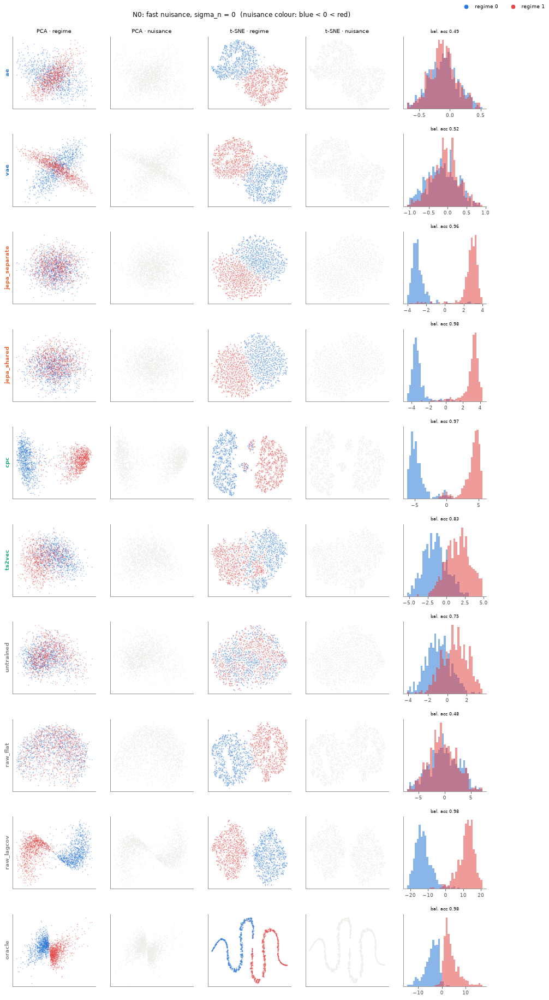

In [21]:
latent_figure("N0")

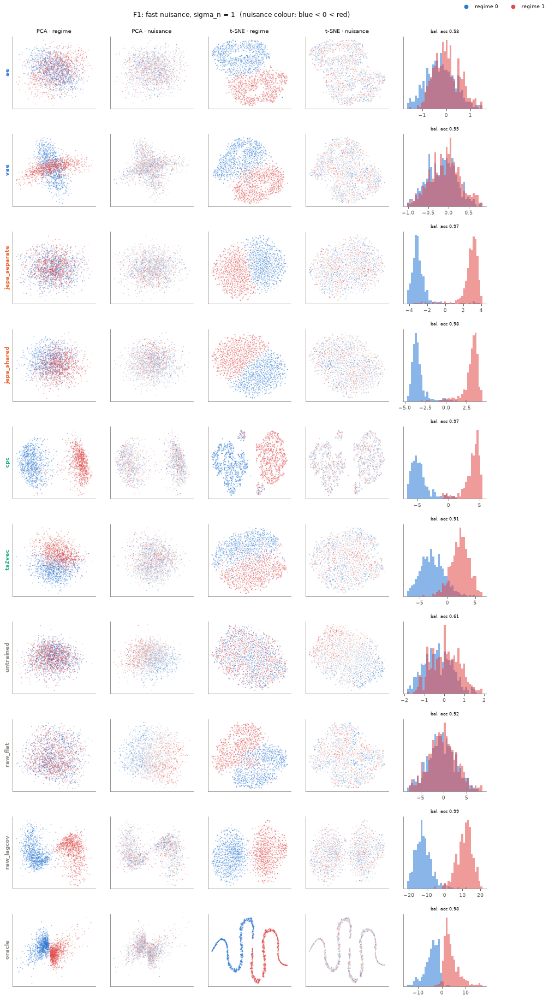

In [22]:
latent_figure("F1")

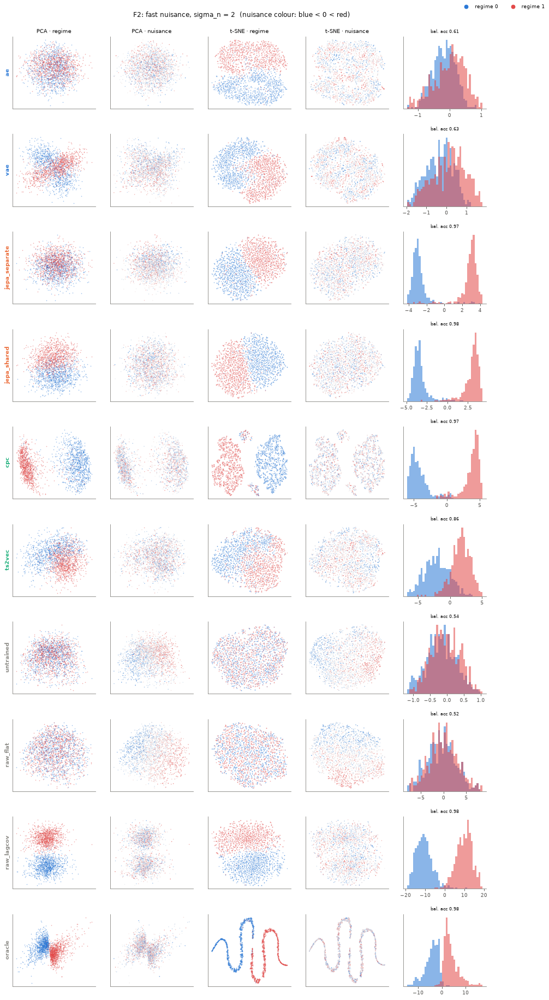

In [23]:
latent_figure("F2")

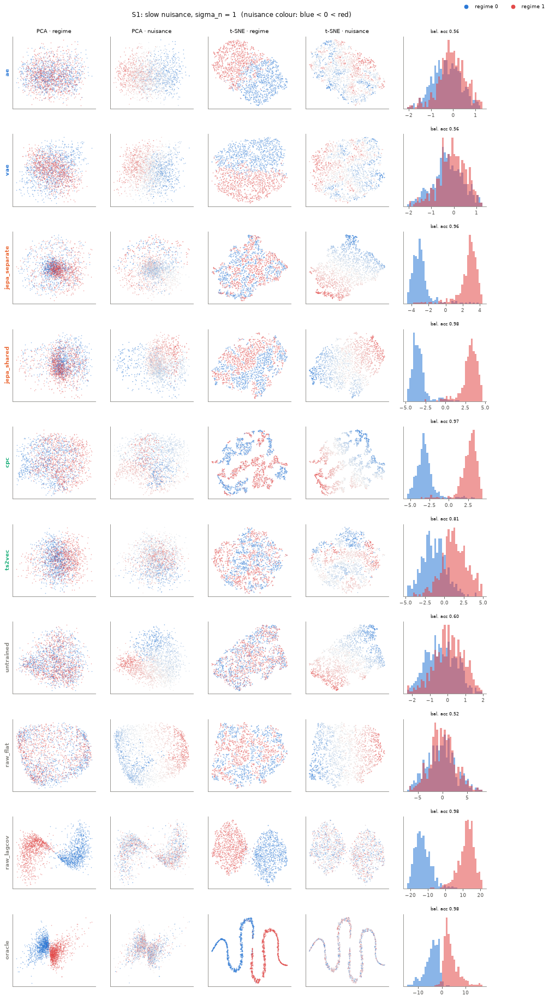

In [24]:
latent_figure("S1")

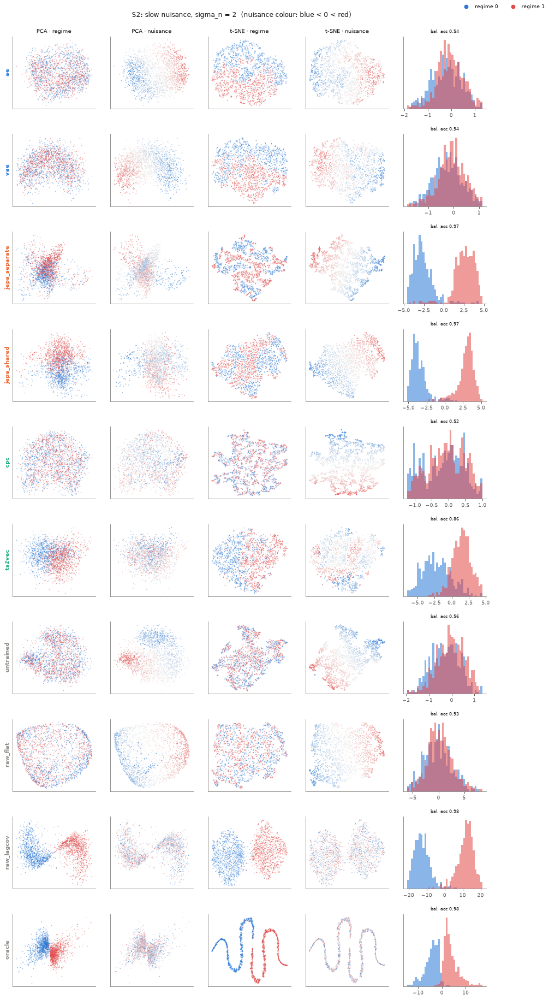

In [25]:
latent_figure("S2")

## 4. Time domain: what the features do over time, and what the HMM decodes

Each panel shows one held-out test series (seed 0) and three normalised traces:

- **black:** the learner's features projected on the **linear regime axis**, a logistic regression fitted on the other
  test series
- **gray:** the features' **first principal component**, the dominant direction an unsupervised model sees first
- **dotted:** the **true nuisance**

The strips underneath compare the true regime with the primary detector's decoding (HMM, k = 16, persistence
selection, refitted here as in scoring). Each HMM state is mapped to its majority regime. On S, the regime axis still
tracks the regime, but PC1 tracks the nuisance, and so does the HMM.

In [26]:
HMM = dict(type="hmm", k=16, select="persistence")
def time_figure(c):
    y, u = win_regime(c), win_nuis(c); R = y.shape[0]; h = R // 2; s0 = h          # display the first held-out series
    keys = TRAINED + ["raw_flat", "raw_lagcov"]
    fig, ax = plt.subplots(len(keys), 1, figsize=(15, 1.75 * len(keys)), sharex=True)
    t = np.arange(y.shape[1]); nz = lambda v: v / (np.abs(v).max() + 1e-9)
    for a, key in zip(ax, keys):
        Z, _ = feats(c, key); d = Z.shape[-1]
        sc = StandardScaler().fit(Z[:h].reshape(-1, d))
        clf = LogisticRegression(C=0.1, max_iter=3000).fit(sc.transform(Z[:h].reshape(-1, d)), y[:h].ravel())
        score = clf.decision_function(sc.transform(Z[s0]))
        pc = PCA(1).fit(sc.transform(Z.reshape(-1, d))).transform(sc.transform(Z[s0]))[:, 0]
        if CONDITIONS[c][1] and np.corrcoef(pc, u[s0])[0, 1] < 0: pc = -pc
        a.fill_between(t, 0, 1, where=y[s0] == 1, transform=a.get_xaxis_transform(), color=RED, alpha=0.12, lw=0)
        a.plot(t, nz(score), color=INK, lw=1.1, label="linear regime axis (fit on other series)")
        a.plot(t, nz(pc), color=MUTED, lw=1, label="feature PC1")
        if CONDITIONS[c][1]: a.plot(t, nz(u[s0]), ":", color=INK2, lw=1, label="true nuisance")
        lab = make_detector(HMM).detect(Z, 2, seed=0)["labels"]
        m = {q: np.bincount(y[lab == q], minlength=2).argmax() for q in np.unique(lab)}
        dec = np.vectorize(m.get)(lab)
        a.bar(t, 0.22, bottom=-1.33, width=1.0, color=[REG[k] for k in y[s0]], lw=0)
        a.bar(t, 0.22, bottom=-1.62, width=1.0, color=[REG[k] for k in dec[s0]], lw=0)
        a.text(-2, -1.22, "truth", ha="right", va="center", fontsize=7, color=INK2)
        a.text(-2, -1.51, "HMM", ha="right", va="center", fontsize=7, color=INK2)
        a.set_ylim(-1.7, 1.1); a.set_yticks([])
        acc = balanced_accuracy_score(y[h:].ravel(), clf.predict(sc.transform(Z[h:].reshape(-1, d))))
        a.text(0.005, 0.97, f"{key}   linear-axis bal. acc {acc:.2f}   HMM window acc {(dec == y).mean():.2f}",
               transform=a.transAxes, color=FAMC[FAMILY[key]], fontsize=8.5, fontweight="bold", va="top")
    ax[0].legend(loc="lower right", bbox_to_anchor=(1, 1.12), ncol=3, fontsize=7.5)
    ax[-1].set_xlabel(f"window index (64 samples each), held-out test series {s0}")
    fig.suptitle(f"{c}: regime 1 shaded; bottom strips = true regime vs HMM-decoded regime (blue 0, red 1)", fontsize=10, x=0.3)
    plt.tight_layout(); plt.show()

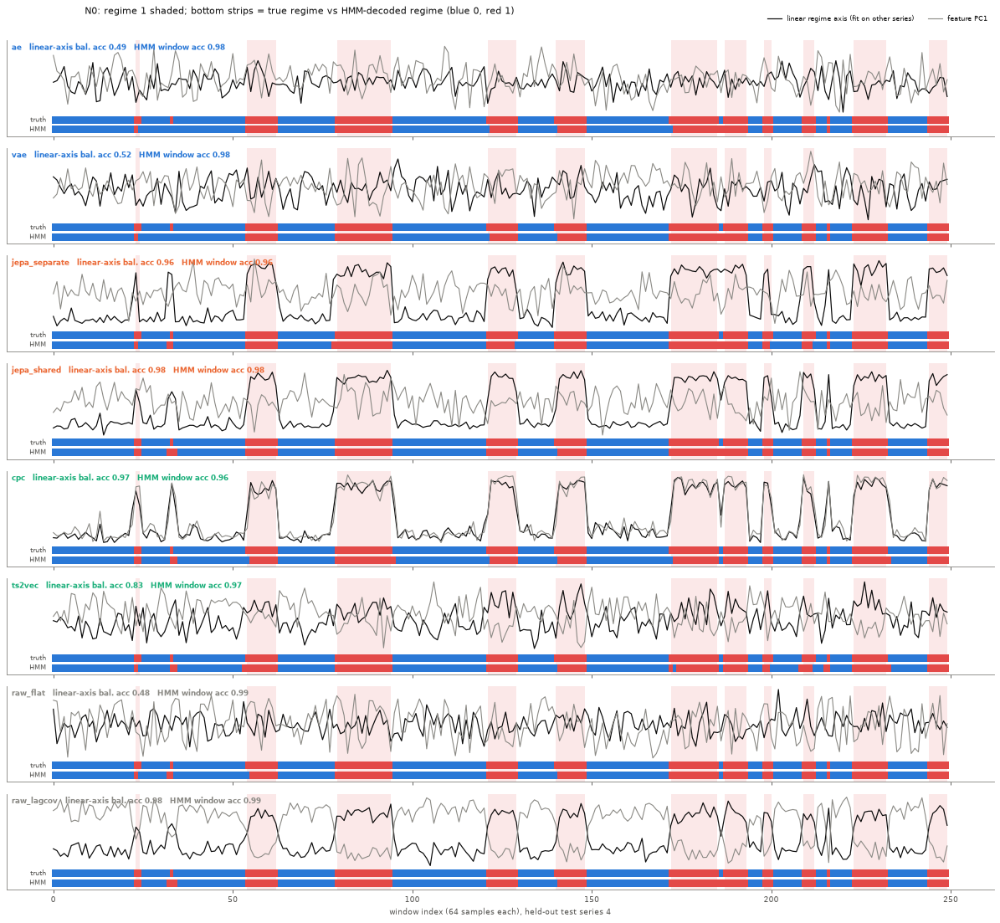

In [27]:
time_figure("N0")

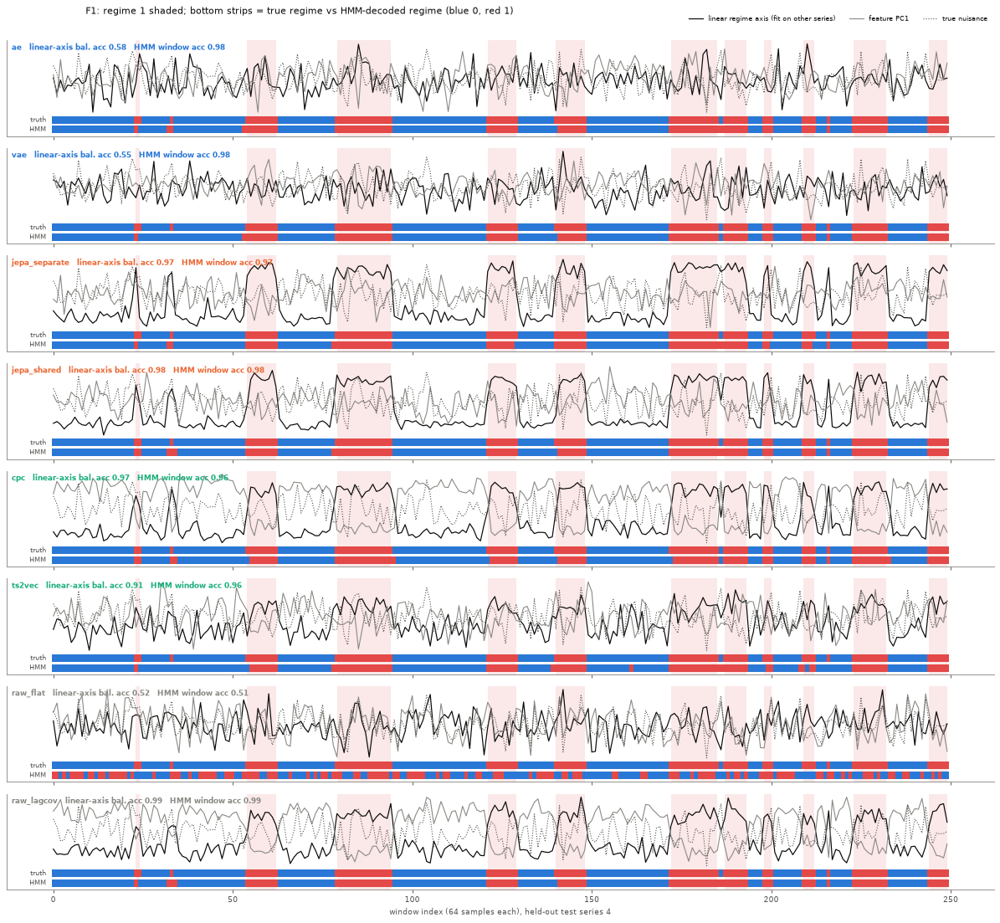

In [28]:
time_figure("F1")

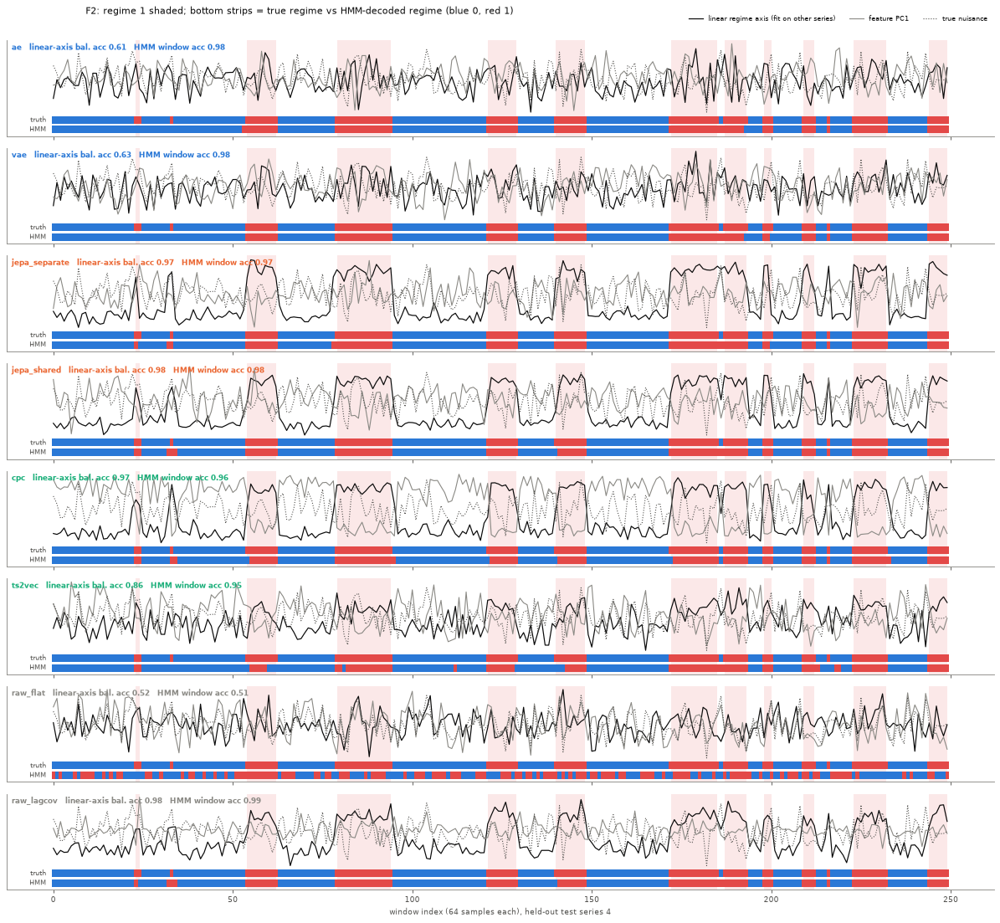

In [29]:
time_figure("F2")

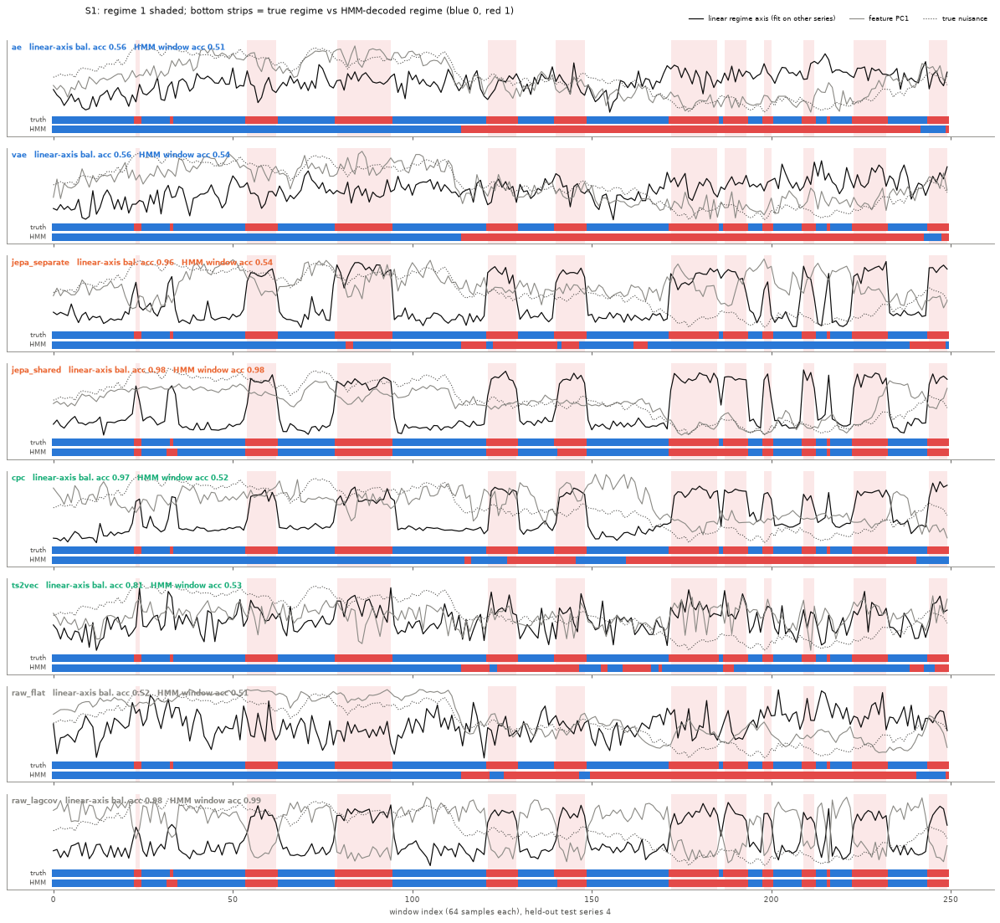

In [30]:
time_figure("S1")

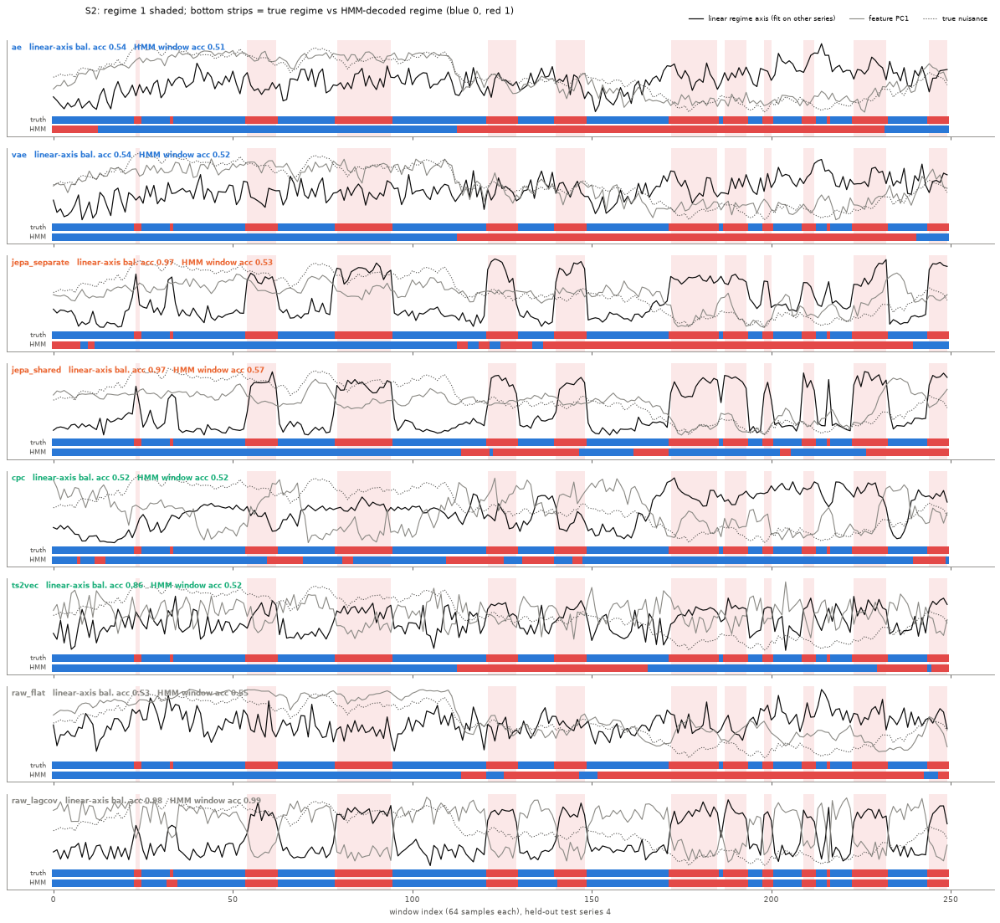

In [31]:
time_figure("S2")

## 5. Training dynamics (20k steps, 3 seeds)

Training loss is shown relative to its value at step 1000 (the collapse gate compares the final value with this).
Effective rank and HMM/GMM accuracy come from the periodic validation checks. Those use the default detector
settings, not the persistence-selected scoring detector, and are for monitoring only. Thin lines are seeds,
thick lines their mean.

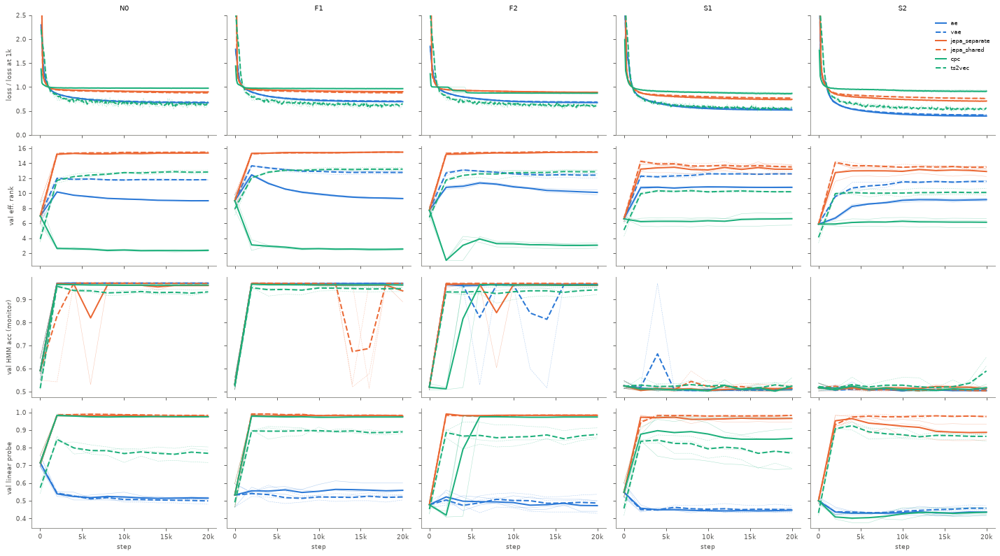

In [32]:
def logs(c, key, seed):
    p = os.path.join(benches[c].run_dir(spec(key, seed)), "log.jsonl")
    recs = [json.loads(l) for l in open(p)]
    tr = pd.DataFrame([r for r in recs if r["kind"] == "train"]); ev = pd.DataFrame([r for r in recs if r["kind"] == "eval"])
    return tr, ev
LS = dict(ae="-", vae="--", jepa_separate="-", jepa_shared="--", cpc="-", ts2vec="--")
rows = [("loss", "loss / loss at 1k", "tr"), ("eff_rank", "val eff. rank", "ev"), ("hmm_acc", "val HMM acc (monitor)", "ev"), ("probe", "val linear probe", "ev")]
fig, axes = plt.subplots(len(rows), 5, figsize=(18, 10), sharex=True, sharey="row")
for j, c in enumerate(CONDS):
    for l in TRAINED:
        curves = {m: [] for m, _, _ in rows}
        for s in (0, 1, 2):
            tr, ev = logs(c, l, s)
            base = tr.loc[tr.step == 1000, "loss"].iloc[0]
            for m, _, src in rows:
                d = tr if src == "tr" else ev
                yv = d[m] / base if m == "loss" else d[m]
                curves[m].append(pd.Series(yv.values, index=d.step.values))
        for i, (m, lab, _) in enumerate(rows):
            a = axes[i, j]
            for cs in curves[m]:
                a.plot(cs.index, cs.values, LS[l], color=FAMC[FAMILY[l]], lw=0.5, alpha=0.35)
            mm = pd.concat(curves[m], axis=1).mean(axis=1)
            a.plot(mm.index, mm.values, LS[l], color=FAMC[FAMILY[l]], lw=1.8, label=l)
            if j == 0: a.set_ylabel(lab)
            if i == 0: a.set_title(c)
axes[0, 0].set_ylim(0, 2.5); axes[0, -1].legend(fontsize=7, loc="upper right")
for a in axes[-1]:
    a.set_xlabel("step"); a.set_xticks([0, 5000, 10000, 15000, 20000], ["0", "5k", "10k", "15k", "20k"])
plt.tight_layout(); plt.show()

## 6. The other experiments

### 6a. Preflight control audit on the fresh evaluation series (part of the confirmatory launch)

These are the controls only, scored before any learner was trained. They supplied the oracle gate (HMM ≥ 0.95
everywhere, passed at 0.959). They also confirm that a hand-built lag-covariance statistic (`raw_lagcov`) recovers
the regime in every condition, and that raw windows do so only without nuisance.

In [33]:
au = pd.read_csv(os.path.join(L, "audit.csv"))
show = ["probe_mlp_single", "probe", "probe_mlp_pair", "nuis_mlp_r2", "nuis_r2", "hmm", "gmm", "hmm_cp_ap", "eff_rank"]
with pd.option_context("display.width", 300):
    display(au.pivot(index="learner", columns="cond", values=show).reindex(["untrained", "raw_flat", "raw_lagcov", "oracle"])[[(m, c) for m in show for c in CONDS]].round(2))
display(pd.read_csv(os.path.join(L, "audit_gates.csv")))

probe_mlp_single                         probe                          ... hmm_cp_ap                         eff_rank                           
cond                     N0    F1    F2    S1    S2    N0    F1    F2    S1    S2  ...        N0    F1    F2    S1    S2       N0     F1     F2     S1    S2
learner                                                                            ...                                                                      
untrained              0.71  0.61  0.55  0.62  0.58  0.75  0.61  0.54  0.60  0.56  ...      0.03  0.02  0.04  0.02  0.01     8.70  10.01   8.31   7.19  6.08
raw_flat               0.96  0.93  0.88  0.94  0.94  0.48  0.52  0.52  0.52  0.53  ...      0.68  0.03  0.04  0.02  0.02    49.77  81.43  61.21  22.28  9.81
raw_lagcov             0.99  0.99  0.98  0.99  0.98  0.98  0.99  0.98  0.98  0.98  ...      0.68  0.69  0.67  0.69  0.69     3.69  14.73  38.45   3.77  4.02
oracle                 0.97  0.97  0.97  0.97  0.97  0.98  0.98  0.98  0.98  0.98  ...      0.50  0.50  0.50  0.50  0.50     1.00   1.00   1.00   1.00  1.00

[4 rows x 45 columns]

,test,verdict,numbers
0,gate: oracle HMM acc >= 0.95 everywhere,pass,"N0 0.959, F1 0.959, F2 0.959, S1 0.959, S2 0.959"


### 6b. The exploratory pilot vs the confirmatory run (context only, never pooled)

The pilot differs from the confirmatory run in almost every respect:

| | pilot | confirmatory run |
|---|---|---|
| code | legacy (pre-`audit_v2`) | current |
| training stream | v1 | v2 |
| training steps | 3k | 20k |
| seeds | 1 | 3 |
| evaluation series | seed 0 | fresh (`eval_seed` 20261016) |
| conditions | N0, F2, S2 | all five |

The pilot's `probe_mlp` is the window-pair probe, so it is compared with `probe_mlp_pair`. Points on the diagonal
replicated. The large miss is the AE on F2 (pilot HMM 0.54, confirmatory 0.97): the pilot failure did not replicate.

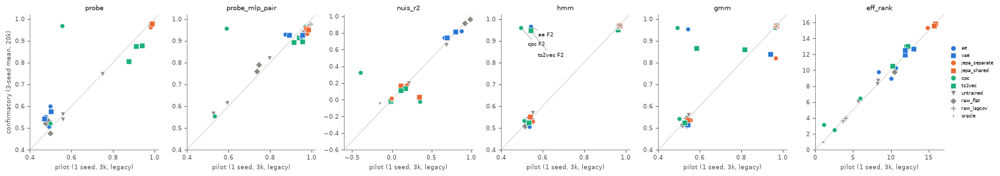

probe_pilot  probe_hpc  probe_mlp_pair_pilot  probe_mlp_pair_hpc  nuis_r2_pilot  nuis_r2_hpc  hmm_pilot  hmm_hpc  gmm_pilot  gmm_hpc  eff_rank_pilot  eff_rank_hpc
cond learner                                                                                                                                                                          
N0   untrained             0.75       0.75                  0.79                0.82          -0.01        -0.02       0.55     0.57       0.55     0.56            8.24          8.70
     raw_flat              0.50       0.48                  0.97                0.94          -0.70        -0.66       0.97     0.97       0.97     0.97           49.69         49.77
     raw_lagcov            0.99       0.98                  0.99                0.98          -0.85        -0.82       0.97     0.97       0.97     0.97            3.66          3.69
     oracle                0.99       0.98                  0.98                0.97          -0.00        -0.00       0.96     0.96       0.97     0.97            1.00          1.00
     ae                    0.49       0.51                  0.97                0.93          -0.02        -0.02       0.97     0.97       0.97     0.97            9.98          9.00
     vae                   0.48       0.53                  0.97                0.95          -0.02        -0.02       0.97     0.97       0.97     0.97           11.90         11.96
     jepa_separate         0.98       0.96                  0.98                0.96          -0.02        -0.02       0.97     0.96       0.97     0.96           15.86         15.86
     jepa_shared           0.99       0.98                  0.98                0.95          -0.02        -0.02       0.97     0.97       0.97     0.97           15.88         15.85
     cpc                   0.98       0.97                  0.97                0.97          -0.02        -0.02       0.96     0.96       0.96     0.96            2.48          2.46
     ts2vec                0.88       0.81                  0.91                0.89          -0.01        -0.02       0.96     0.95       0.82     0.86           12.01         12.94
F2   untrained             0.56       0.54                  0.53                0.57           0.21         0.20       0.52     0.50       0.52     0.51            8.22          8.31
     raw_flat              0.47       0.52                  0.74                0.79           0.91         0.92       0.51     0.51       0.52     0.51           59.70         61.21
     raw_lagcov            0.99       0.98                  0.98                0.97          -0.63        -0.54       0.97     0.97       0.97     0.97           38.97         38.45
     oracle                0.99       0.98                  0.98                0.97          -0.00        -0.00       0.96     0.96       0.97     0.97            1.00          1.00
     ae                    0.50       0.60                  0.87                0.93           0.66         0.74       0.54     0.97       0.54     0.95           10.66         10.26
     vae                   0.50       0.57                  0.89                0.93           0.70         0.74       0.97     0.97       0.94     0.84           12.99         12.71
     jepa_separate         0.98       0.97                  0.97                0.95           0.18         0.18       0.97     0.96       0.97     0.82           15.86         15.86
     jepa_shared           0.99       0.98                  0.98                0.96           0.11         0.17       0.97     0.97       0.97     0.97           15.89         15.87
     cpc                   0.55       0.97                  0.59                0.96           0.35        -0.02       0.49     0.96       0.49     0.96            1.13          3.16
     ts2vec                0.91       0.88                  0.94                0.92           0.17         0.14       0.54     0.95       0.58     0.87           12.23         

In [34]:
pil = pd.read_csv("cpbench_results/recon_vs_pred_pilot.csv").rename(columns={"probe_mlp": "probe_mlp_pair"})
hm = df.groupby(["cond", "learner"]).mean(numeric_only=True).reset_index()
both = pil.merge(hm, on=["cond", "learner"], suffixes=("_pilot", "_hpc"))
MS = ["probe", "probe_mlp_pair", "nuis_r2", "hmm", "gmm", "eff_rank"]
fig, axes = plt.subplots(1, len(MS), figsize=(19, 3.4))
for a, m in zip(axes, MS):
    lo, hi = (0, 17) if m == "eff_rank" else (-0.6, 1.02) if m == "nuis_r2" else (0.4, 1.02)
    a.plot([lo, hi], [lo, hi], color=RULE, lw=1.5, zorder=0)
    for r in both.itertuples():
        a.scatter(getattr(r, m + "_pilot"), getattr(r, m + "_hpc"), marker=MARK[r.learner], color=FAMC[FAMILY[r.learner]],
                  s=40, edgecolor="white", lw=0.6)
        if m == "hmm" and abs(getattr(r, m + "_pilot") - getattr(r, m + "_hpc")) > 0.2:
            k = sum(1 for _ in a.texts)
            a.annotate(f"{r.learner} {r.cond}", (getattr(r, m + "_pilot"), getattr(r, m + "_hpc")), fontsize=7, xytext=(10, -14 - 11 * k),
                       textcoords="offset points", arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.6))
    a.set_xlim(lo, hi); a.set_ylim(lo, hi); a.set_title(m); a.set_xlabel("pilot (1 seed, 3k, legacy)")
axes[0].set_ylabel("confirmatory (3-seed mean, 20k)")
axes[-1].legend(handles=learner_handles(), fontsize=6.5, loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout(); plt.show()
with pd.option_context("display.width", 300):
    display(both.set_index(["cond", "learner"])[[f"{m}_{k}" for m in MS for k in ("pilot", "hpc")]].round(2))

### 6c. CPC trainability check (label-free, before HPC release)

F2, seed 0, 3k steps. Selection used only the loss ratio (rule < 0.9) and the effective rank (rule > 2). No setting
passed, so CPC kept its defaults and was pre-declared "failed to train". In the confirmatory run none of its 15 runs
collapsed, but it lost the regime on S2.

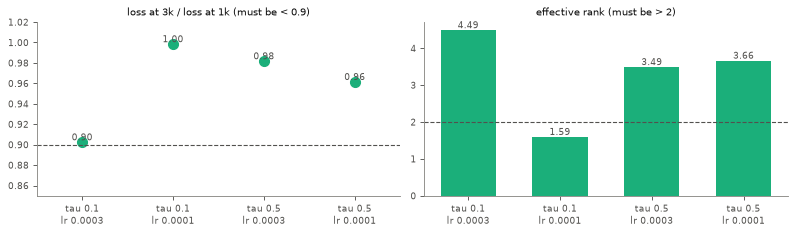

In [35]:
cc = pd.read_csv("cpbench_results/recon_vs_pred_cpc_check.csv")
lab = [f"tau {r.temperature:g}\nlr {r.lr:g}" for r in cc.itertuples()]
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for a, (m, thr, name) in zip(ax, (("loss_ratio", 0.9, "loss at 3k / loss at 1k (must be < 0.9)"), ("eff_rank", 2, "effective rank (must be > 2)"))):
    if m == "loss_ratio":
        a.plot(range(len(cc)), cc[m], "o", color=AQUA, ms=9)
    else:
        a.bar(range(len(cc)), cc[m], color=AQUA, width=0.6)
    a.axhline(thr, ls="--", color=INK2, lw=1)
    for i, v in enumerate(cc[m]): a.text(i, v, f"{v:.2f}", ha="center", va="bottom", color=INK2, fontsize=8)
    a.set_xticks(range(len(cc)), lab); a.set_title(name)
ax[0].set_ylim(0.85, 1.02); ax[0].set_xlim(-0.5, len(cc) - 0.5)
plt.tight_layout(); plt.show()